# YES BANK | Regime-Aware Multi-Horizon Stock Forecasting

### A leakage-safe financial machine-learning study with walk-forward validation, uncertainty bands and decision analysis

**Project type:** Regression · Time-series forecasting · Secondary direction classification
**Author / contribution:** `Rahul` · `Individual`  
**GitHub:** https://github.com/Mr-rxa/yes-bank-ds

## Executive summary

This project develops and audits a monthly stock-price forecasting workflow for YES BANK using the supplied historical OHLC dataset. Rather than treating a random train/test split as valid for time series, the study frames the task as a sequence of forecasts made at a known monthly close. At each forecast origin, only information available by that date is used. The principal targets are the log returns from the current close to the close one, three and six months ahead. Predicted log returns are converted back into rupee closing-price estimates, preserving positive price predictions and allowing model performance to be interpreted in business units.

The dataset contains 185 monthly observations from July 2005 through November 2020 and five original columns: Date, Open, High, Low and Close. The workflow validates dates, numeric fields, positive prices, OHLC price ordering, duplicate dates and missing values before feature construction. Features are intentionally derived from information available at the forecast origin: lagged returns, rolling return means and volatility, momentum, moving-average gaps, relative intramonth range, opening gap, candle body, RSI-style indicators and cyclical month encodings. Rolling features are not backfilled from future observations. The initial rows lost to indicator lookback windows are removed transparently rather than fabricated through imputation.

The modelling design compares interpretable regularized linear models with tree-based nonlinear models. Candidate hyperparameters are selected through expanding-window time-series cross-validation on the development period. A gap is inserted between training and validation folds so that labels whose future target date has not yet arrived are not used to train a forecast. A final chronological holdout is left untouched during model selection. During holdout evaluation, the selected model is refitted in a walk-forward manner only when the corresponding historical target has become observable. This better reflects the information flow of a real forecasting process than fitting once on the full dataset.

A strong persistence benchmark (predicting no change from the latest close), a historical-drift benchmark and a same-calendar-month seasonal benchmark are reported alongside the machine-learning models. Evaluation includes MAE and RMSE in rupees, percentage errors, log-return errors and directional accuracy. The notebook also produces approximate empirical prediction bands from out-of-fold residuals, investigates residual autocorrelation, estimates permutation-based feature importance, and tests whether a simple long/flat signal could have added value after an explicit transaction-cost assumption. A secondary direction-classification experiment is included as a supporting signal, not as a substitute for price forecasting.

The purpose is not to force a complex model to win. If the machine-learning forecast does not improve on simple benchmarks in the untouched holdout, the correct conclusion is that the available OHLC history has not demonstrated sufficient incremental predictive value. That result is more credible—and more useful for a business decision—than reporting an attractive training score. The study closes with model limitations, reproducibility instructions, saved model artifacts and a monitoring plan. Any future live deployment would require fresh, properly licensed data, current market benchmarks, corporate-action adjustments, realistic execution assumptions and repeated out-of-time validation.

## Problem statement and business objective

**Problem statement.** Given only the OHLC observations available up to a monthly close, estimate YES BANK's closing price one, three and six months ahead. Determine whether engineered historical-price signals improve on transparent naïve forecasts, and quantify uncertainty and downside risk.

**Business objective.** Produce an auditable forecasting prototype that supports historical scenario analysis and risk review. The model is a decision-support experiment, not an automated trading recommendation.

### What makes this study stronger than a basic regression notebook?

1. Forecast targets are **future log returns**, then transformed to closing prices; the model does not learn a static correlation between contemporaneous OHLC columns and Close.
2. **Chronological validation with a horizon-aware gap** prevents future labels from entering training folds.
3. **Walk-forward holdout predictions** mimic how forecasts are made and updated through time.
4. Results are benchmarked against persistence, drift and seasonal-naïve forecasts.
5. The notebook evaluates **1-, 3- and 6-month horizons**, reports empirical uncertainty bands, residual tests and model interpretation.
6. A simple strategy simulation includes user-visible trading-cost assumptions and compares against buy-and-hold.

### Scope and guardrails

- The data frequency is monthly; no intraday claims are made.
- Only information present in the supplied CSV is used.
- No future OHLC value is used as a predictor for an earlier forecast origin.
- The final chronological holdout is not used for hyperparameter selection.
- Outliers are inspected, not automatically deleted: extreme moves may be genuine market observations.
- The last-row forecast is explicitly labelled historical because the source ends in November 2020.

## Contents

1. Environment and reproducibility  
2. Load data and run quality controls  
3. Data understanding and exploratory analysis  
4. Hypothesis tests and time-series diagnostics  
5. Leakage-safe feature engineering  
6. Time-aware split and baseline forecasts  
7. Model development, tuning and walk-forward evaluation  
8. Direction classification (secondary experiment)  
9. Uncertainty quantification and residual diagnostics  
10. Feature interpretation and volatility-regime review  
11. Strategy simulation and business decision  
12. Historical multi-horizon forecast, model export and conclusion

# 1. Environment and reproducibility

The notebook uses common Python packages available in a standard data-science environment. It does not download data or call paid APIs. Random seeds are fixed for reproducibility. If a package is missing locally, install the listed requirement before running all cells.

In [1]:
# Core libraries
import json
import math
import os
import platform
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.stats import mannwhitneyu

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, ElasticNet, LogisticRegression
from sklearn.ensemble import (
    RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import TimeSeriesSplit, ParameterGrid
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, brier_score_loss, confusion_matrix,
    roc_curve, classification_report
)
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.dummy import DummyClassifier
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf
import statsmodels.api as sm
import joblib

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

# Do not hide every warning: warnings can reveal compatibility or data issues.
print('Python:', platform.python_version())
print('pandas:', pd.__version__)
print('NumPy:', np.__version__)
print('scikit-learn:', __import__('sklearn').__version__)
print('statsmodels:', sm.__version__)

Python: 3.13.3
pandas: 3.0.3
NumPy: 2.4.6
scikit-learn: 1.9.0
statsmodels: 0.14.6


### Reproducibility settings

The experiment is deterministic where the estimator supports a random seed. The train/test boundary is time-based and fixed relative to the dataset length. All tuned model parameters, feature names, target horizon and source data cutoff are saved with the final model bundle.

# 2. Load data and run quality controls

In [2]:
# Find the CSV in the notebook folder or common mounted-data locations.
CANDIDATE_FILES = [
    Path('data_YesBank_StockPrices(1).csv'),
    Path('data_YesBank_StockPrices.csv'),
    Path('./data/data_YesBank_StockPrices.csv'),
    Path('/mnt/data/data_YesBank_StockPrices(1).csv'),
    Path('/mnt/data/data_YesBank_StockPrices.csv'),
]
DATA_PATH = next((p for p in CANDIDATE_FILES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        'YES BANK CSV not found. Place data_YesBank_StockPrices.csv in the same folder as this notebook.'
    )

raw = pd.read_csv(DATA_PATH)
required_columns = {'Date', 'Open', 'High', 'Low', 'Close'}
missing_columns = required_columns.difference(raw.columns)
if missing_columns:
    raise ValueError(f'Dataset is missing required columns: {sorted(missing_columns)}')

# Parse the month labels used in the supplied file (e.g. Jul-05).
df = raw.copy()
df['Date'] = pd.to_datetime(df['Date'], format='%b-%y', errors='coerce')
if df['Date'].isna().any():
    bad = raw.loc[df['Date'].isna(), 'Date'].head(5).tolist()
    raise ValueError(f'Unparseable date labels found: {bad}')

for col in ['Open', 'High', 'Low', 'Close']:
    df[col] = pd.to_numeric(df[col], errors='coerce')
if df[['Open', 'High', 'Low', 'Close']].isna().any().any():
    raise ValueError('One or more OHLC values are missing or non-numeric.')

df = df.sort_values('Date').reset_index(drop=True)
if df['Date'].duplicated().any():
    raise ValueError('Duplicate monthly dates found. Resolve them before modelling.')
if (df[['Open', 'High', 'Low', 'Close']] <= 0).any().any():
    raise ValueError('OHLC prices must be positive for log-return modelling.')
if (df['High'] < df[['Open', 'Close']].max(axis=1)).any():
    raise ValueError('OHLC validation failed: High is below Open or Close on at least one row.')
if (df['Low'] > df[['Open', 'Close']].min(axis=1)).any():
    raise ValueError('OHLC validation failed: Low is above Open or Close on at least one row.')

print(f'Source file: {DATA_PATH.resolve()}')
print(f'Shape: {df.shape[0]} rows × {df.shape[1]} columns')
print(f'Period: {df.Date.min():%B %Y} to {df.Date.max():%B %Y}')
print('Missing values:', int(df.isna().sum().sum()))
print('Duplicate rows:', int(df.duplicated().sum()))
print('Duplicate dates:', int(df.Date.duplicated().sum()))
display(df.head())

Source file: C:\Users\sharm\Downloads\yes_bank\data_YesBank_StockPrices.csv
Shape: 185 rows × 5 columns
Period: July 2005 to November 2020
Missing values: 0
Duplicate rows: 0
Duplicate dates: 0


,Date,Open,High,Low,Close
0,2005-07-01,13.0000,14.0000,11.2500,12.4600
1,2005-08-01,12.5800,14.8800,12.5500,13.4200
2,2005-09-01,13.4800,14.8700,12.2700,13.3000
3,2005-10-01,13.2000,14.4700,12.4000,12.9900
4,2005-11-01,13.3500,13.8800,12.8800,13.4100


In [3]:
# Structural and statistical overview
print('Data types:')
display(df.dtypes.to_frame('dtype'))
print('Descriptive statistics:')
display(df[['Open', 'High', 'Low', 'Close']].describe().T)
print('Date cadence check (month differences):')
month_number = df['Date'].dt.year * 12 + df['Date'].dt.month
month_steps = month_number.diff().dropna().astype(int)
print(month_steps.value_counts().sort_index())
if not (month_steps == 1).all():
    print('WARNING: The date series has missing or irregular monthly steps; investigate before interpreting horizon labels.')
else:
    print('All consecutive observations are one calendar month apart.')

Data types:


,dtype
Date,datetime64[us]
Open,float64
High,float64
Low,float64
Close,float64


Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
Open,185.0000,105.5414,98.8798,10.0000,33.8000,62.9800,153.0000,369.9500
High,185.0000,116.1043,106.3335,11.2400,36.1400,72.5500,169.1900,404.0000
Low,185.0000,94.9478,91.2194,5.5500,28.5100,58.0000,138.3500,345.5000
Close,185.0000,105.2047,98.5832,9.9800,33.4500,62.5400,153.3000,367.9000


Date cadence check (month differences):
Date
1    184
Name: count, dtype: int64
All consecutive observations are one calendar month apart.


### Data dictionary

| Field | Meaning | Modelling use |
|---|---|---|
| `Date` | Monthly observation date | Time index and cyclical month features |
| `Open` | Opening price | Current-period gap/body/range features |
| `High` | Highest price in the period | Intramonth range feature |
| `Low` | Lowest price in the period | Intramonth range and close location |
| `Close` | Closing price | Forecast anchor and future target |

**Data quality decision:** The file is complete and OHLC ordering is validated. This dataset does not contain a volume field or exogenous market variables, so the project will not invent them.

# 3. Exploratory analysis: the market history before modelling

Exploration is used to describe the source series and motivate the feature design. It is not used to select hyperparameters or to look at the final holdout outcomes.

In [4]:
# Basic return and risk series used in exploratory charts.
eda = df.copy()
eda['Log_Close'] = np.log(eda['Close'])
eda['Log_Return'] = eda['Log_Close'].diff()
eda['Simple_Return_Pct'] = eda['Close'].pct_change() * 100
eda['Range_Pct'] = (eda['High'] - eda['Low']) / eda['Close'].shift(1) * 100
eda['Rolling_Vol_12'] = eda['Log_Return'].rolling(12).std() * np.sqrt(12)
eda['Peak_Close'] = eda['Close'].cummax()
eda['Drawdown_Pct'] = (eda['Close'] / eda['Peak_Close'] - 1) * 100

print('Largest monthly log-return observations:')
display(eda.loc[eda['Log_Return'].abs().nlargest(8).index,
                ['Date', 'Open', 'High', 'Low', 'Close', 'Log_Return']].sort_values('Date'))

Largest monthly log-return observations:


,Date,Open,High,Low,Close,Log_Return
39,2008-10-01,24.6000,25.0000,11.0100,13.5800,-0.5749
45,2009-04-01,10.0400,17.5100,9.9400,15.4500,0.4370
46,2009-05-01,15.9400,28.8400,14.7600,25.1200,0.4861
158,2018-09-01,347.2000,350.0000,166.1500,183.4500,-0.6270
165,2019-04-01,277.0000,285.9000,165.3000,168.0000,-0.4930
171,2019-10-01,42.0000,76.6500,29.0500,70.4500,0.5304
176,2020-03-01,35.2000,87.9500,5.5500,22.4500,-0.4311
180,2020-07-01,25.6000,28.3000,11.1000,11.9500,-0.7619


## Chart 1 — Closing price and 12-month moving averages

**Why this chart?** A time-series line plot shows the long-run level and direction of the stock price. Moving averages smooth short-term noise without using future observations.  
**How to interpret it:** A rising or falling average describes historical price direction, not a causal explanation.  
**Business relevance:** It helps identify long periods of appreciation or deterioration, but a moving average is a descriptive indicator rather than a guaranteed trading signal.

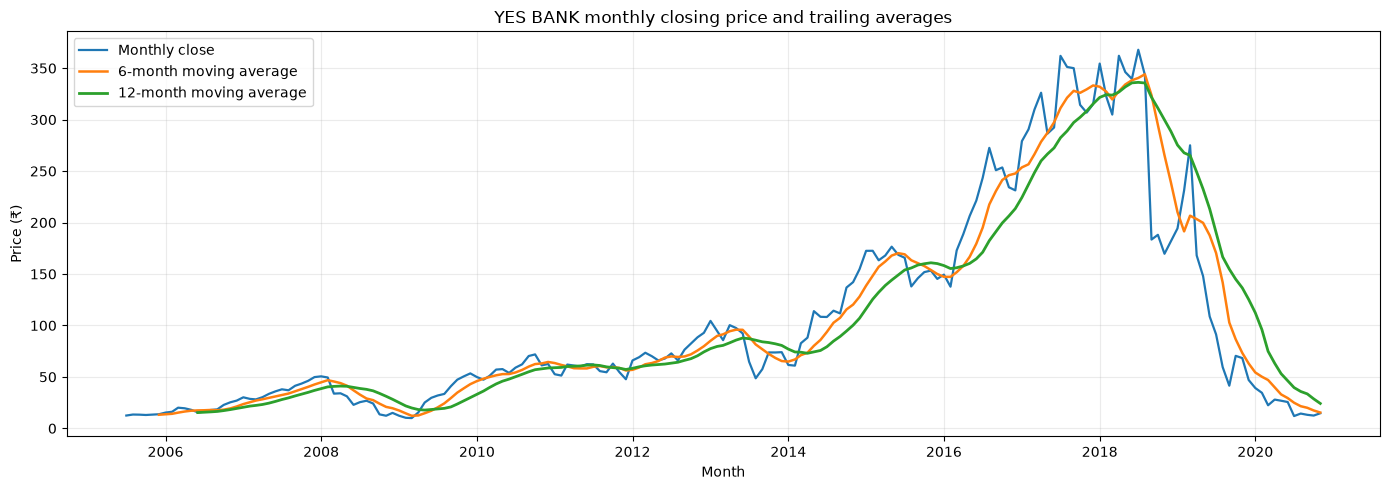

In [5]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df['Date'], df['Close'], label='Monthly close', linewidth=1.6)
ax.plot(df['Date'], df['Close'].rolling(6).mean(), label='6-month moving average', linewidth=1.8)
ax.plot(df['Date'], df['Close'].rolling(12).mean(), label='12-month moving average', linewidth=2)
ax.set(title='YES BANK monthly closing price and trailing averages', xlabel='Month', ylabel='Price (₹)')
ax.legend(); ax.grid(alpha=.25); fig.tight_layout(); plt.show()

## Chart 2 — Monthly log returns

**Why this chart?** Prices are non-stationary in level for many financial series. Log returns put the analysis on a relative-change scale and make positive and negative monthly movements easier to compare.  
**Insight to inspect:** Look for isolated large spikes and periods where movements cluster. These observations motivate robust validation and volatility analysis.  
**Business relevance:** Large moves can create large forecast errors and should be visible to risk reviewers.

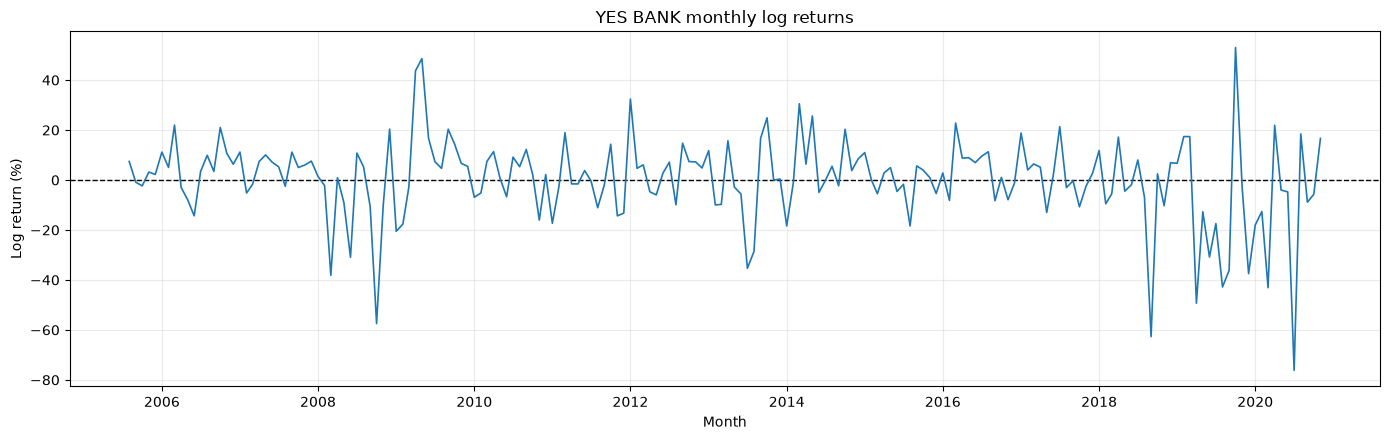

In [6]:
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.axhline(0, color='black', linewidth=1, linestyle='--')
ax.plot(eda['Date'], eda['Log_Return'] * 100, linewidth=1.2)
ax.set(title='YES BANK monthly log returns', xlabel='Month', ylabel='Log return (%)')
ax.grid(alpha=.25); fig.tight_layout(); plt.show()

## Chart 3 — Trailing 12-month realized volatility

**Why this chart?** Rolling standard deviation reveals how return variability changes through time. The calculation uses the current and preceding observations only.  
**Insight to inspect:** Volatility spikes indicate risk regimes in which forecasts may be less reliable.  
**Business relevance:** Risk controls and prediction intervals should respond to changing volatility; a single average-error number can conceal regime-specific failures.

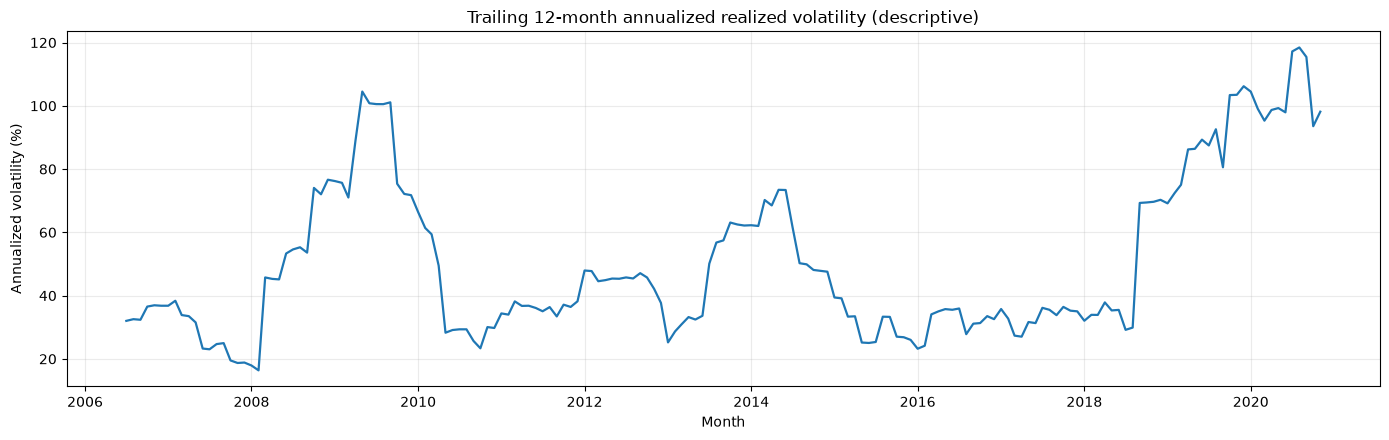

In [7]:
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(eda['Date'], eda['Rolling_Vol_12'] * 100, linewidth=1.6)
ax.set(title='Trailing 12-month annualized realized volatility (descriptive)', xlabel='Month', ylabel='Annualized volatility (%)')
ax.grid(alpha=.25); fig.tight_layout(); plt.show()

## Chart 4 — Drawdown from the prior peak

**Why this chart?** Drawdown measures the decline from the highest close observed up to each date. It presents downside history more clearly than plotting price alone.  
**Insight to inspect:** Deep and persistent negative drawdowns indicate long recovery periods and material downside exposure.  
**Business relevance:** A forecast that has lower MAE but systematically misses drawdowns may still be unsuitable for risk-sensitive decisions.

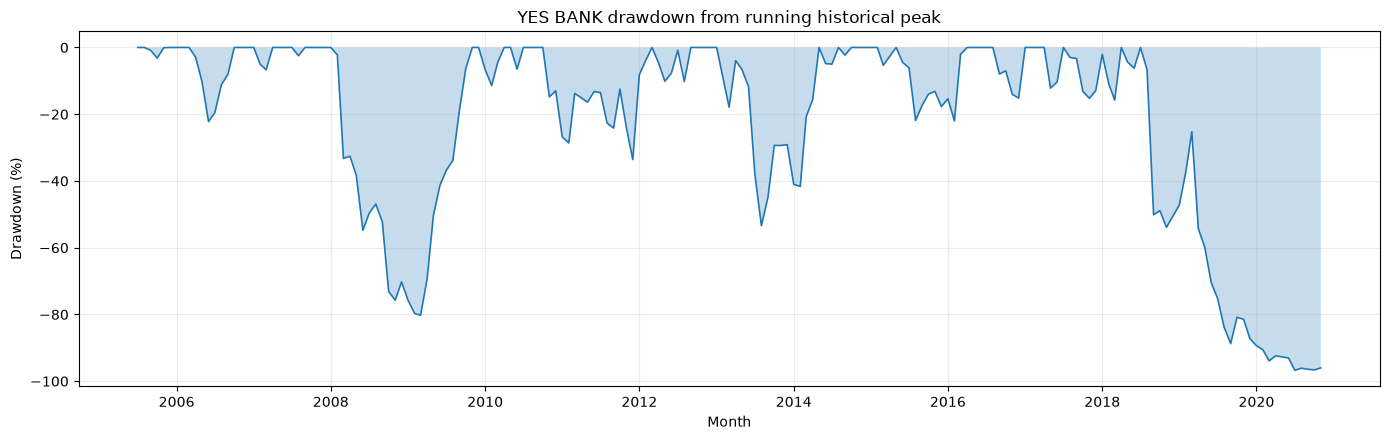

Maximum historical drawdown in this sample: -96.8%


In [8]:
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.fill_between(eda['Date'], eda['Drawdown_Pct'], 0, alpha=.25)
ax.plot(eda['Date'], eda['Drawdown_Pct'], linewidth=1.2)
ax.set(title='YES BANK drawdown from running historical peak', xlabel='Month', ylabel='Drawdown (%)')
ax.grid(alpha=.25); fig.tight_layout(); plt.show()
print(f"Maximum historical drawdown in this sample: {eda['Drawdown_Pct'].min():.1f}%")

## Chart 5 — Distribution of monthly log returns

**Why this chart?** A histogram with a density overlay displays concentration, skewness and tail behaviour.  
**Insight to inspect:** Heavy tails or asymmetry warn against relying on normal-error assumptions without checking them.  
**Business relevance:** Return distributions inform uncertainty reporting and stress testing; extreme observations should not be silently removed.

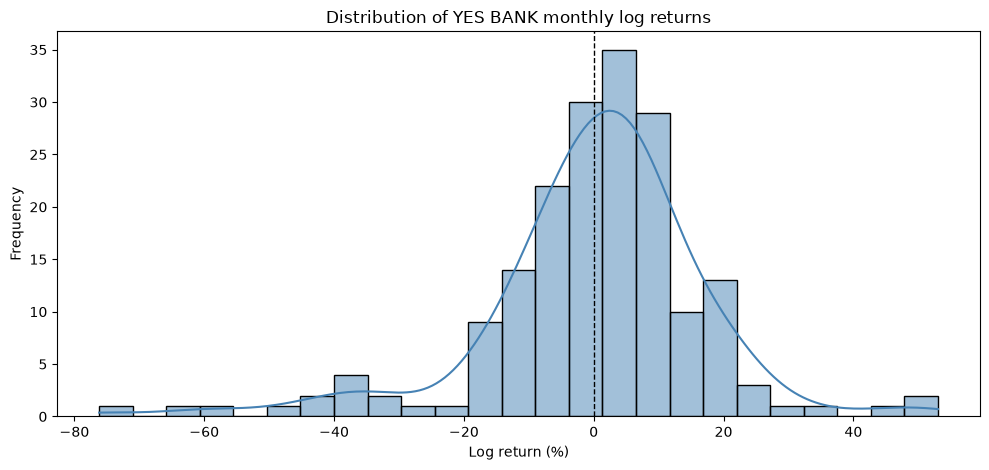

Skewness: -1.002 | Excess kurtosis: 3.893


In [9]:
returns = eda['Log_Return'].dropna()
fig, ax = plt.subplots(figsize=(10, 4.8))
sns.histplot(returns * 100, bins=25, kde=True, color='steelblue', ax=ax)
ax.axvline(0, color='black', linestyle='--', linewidth=1)
ax.set(title='Distribution of YES BANK monthly log returns', xlabel='Log return (%)', ylabel='Frequency')
fig.tight_layout(); plt.show()
print('Skewness:', round(float(returns.skew()), 3), '| Excess kurtosis:', round(float(returns.kurtosis()), 3))

## Chart 6 — Month-of-year return seasonality

**Why this chart?** A month-of-year box plot compares the distribution of returns for January through December, rather than comparing raw prices across different years.  
**Insight to inspect:** Differences may suggest seasonal effects, but the small sample (roughly 15 observations per calendar month) limits confidence.  
**Business relevance:** Seasonality can be explored as a feature, but it should not be assumed to persist without out-of-time evidence.

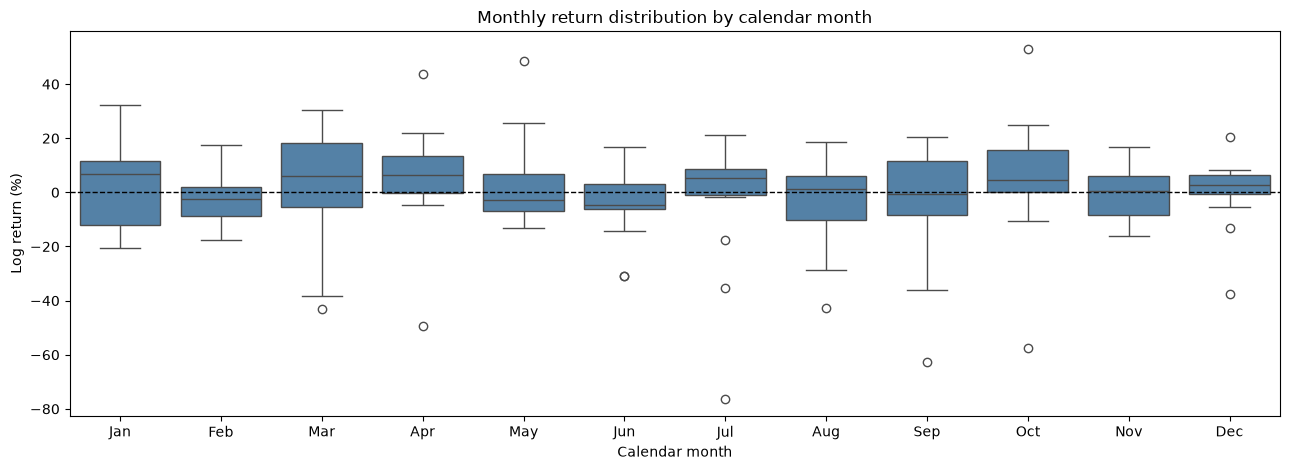

In [10]:
season = eda.dropna(subset=['Log_Return']).copy()
season['Calendar_Month'] = season['Date'].dt.month_name().str[:3]
month_order = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
fig, ax = plt.subplots(figsize=(13, 4.8))
sns.boxplot(data=season, x='Calendar_Month', y=season['Log_Return'] * 100,
            order=month_order, color='steelblue', ax=ax)
ax.axhline(0, color='black', linestyle='--', linewidth=1)
ax.set(title='Monthly return distribution by calendar month', xlabel='Calendar month', ylabel='Log return (%)')
fig.tight_layout(); plt.show()

## Chart 7 — Intramonth range versus absolute return

**Why this chart?** The scatter plot checks whether a wider high-low range tends to coincide with a larger close-to-close move.  
**Insight to inspect:** A positive association would suggest range contains information about the magnitude of movement, but does not establish direction.  
**Business relevance:** Range-based indicators can support a risk model even when they do not predict whether the next month will rise or fall.

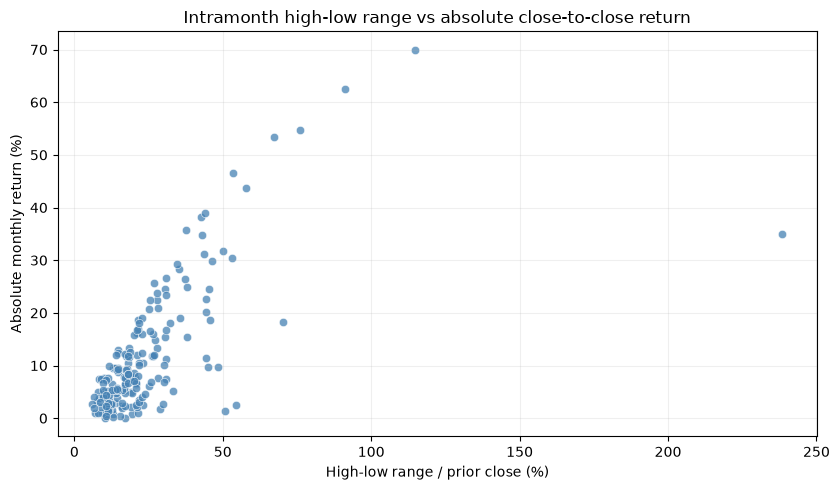

Spearman rank correlation: 0.686


In [11]:
plot_df = eda.dropna(subset=['Range_Pct', 'Simple_Return_Pct']).copy()
fig, ax = plt.subplots(figsize=(8.5, 5))
sns.scatterplot(data=plot_df, x='Range_Pct', y=plot_df['Simple_Return_Pct'].abs(), alpha=.75, color='steelblue', ax=ax)
ax.set(title='Intramonth high-low range vs absolute close-to-close return',
       xlabel='High-low range / prior close (%)', ylabel='Absolute monthly return (%)')
ax.grid(alpha=.2); fig.tight_layout(); plt.show()
print('Spearman rank correlation:', round(float(plot_df['Range_Pct'].corr(plot_df['Simple_Return_Pct'].abs(), method='spearman')), 3))

## Chart 8 — Return autocorrelation and squared-return autocorrelation

**Why this chart?** The paired ACF plots help distinguish serial dependence in return direction from persistence in return magnitude (volatility clustering).  
**Insight to inspect:** Significant autocorrelation in squared returns suggests volatility clustering even when raw returns have little linear autocorrelation.  
**Business relevance:** If risk is persistent, rolling volatility features and volatility-aware monitoring may be more useful than a simple price-only model.

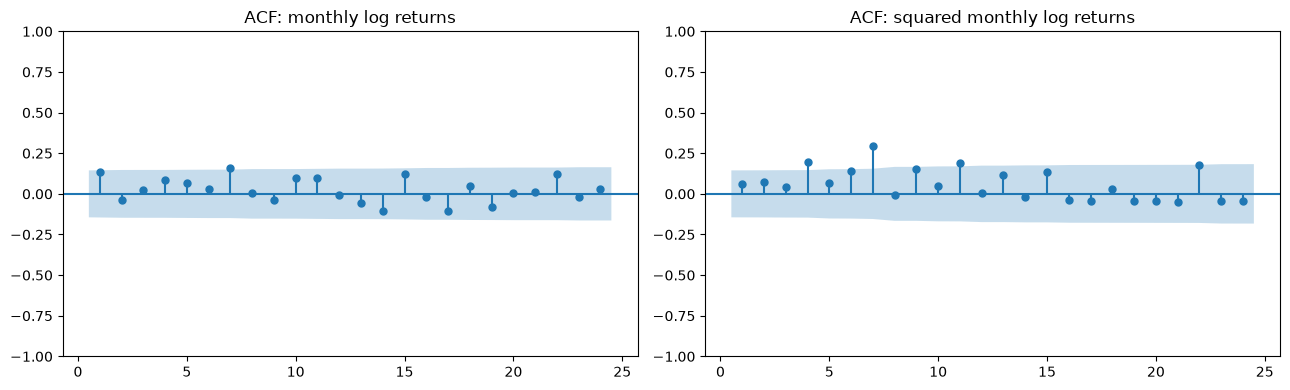

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_acf(returns, lags=24, ax=axes[0], zero=False)
plot_acf(returns ** 2, lags=24, ax=axes[1], zero=False)
axes[0].set_title('ACF: monthly log returns')
axes[1].set_title('ACF: squared monthly log returns')
fig.tight_layout(); plt.show()

## Chart 9 — OHLC correlations (descriptive)

**Why this chart?** A correlation heatmap summarizes linear co-movement among contemporaneous Open, High, Low and Close.  
**Insight to inspect:** High correlations are expected because the columns describe the same monthly price bar. They do **not** prove that one field causes another or that the fields are valid same-month predictors of a future target.  
**Business relevance:** The chart is useful for data understanding; the forecasting model instead uses lagged/derived features and a future-return target.

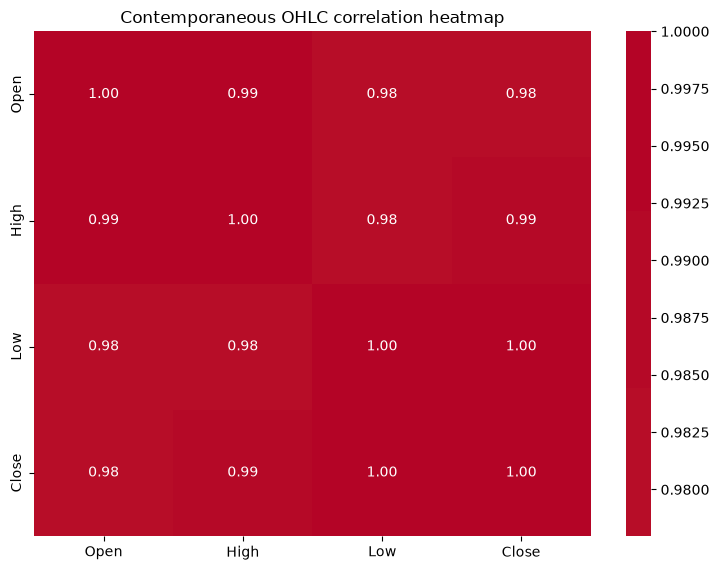

In [13]:
fig, ax = plt.subplots(figsize=(7.5, 5.8))
sns.heatmap(df[['Open','High','Low','Close']].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax)
ax.set_title('Contemporaneous OHLC correlation heatmap')
fig.tight_layout(); plt.show()

## Chart 10 — Close location within the monthly candle

**Why this chart?** The close-location value shows where the close lies between the period low and high. It is scaled to a 0–1 range and therefore more comparable across price levels than rupee range alone.  
**Insight to inspect:** A concentration near 1 means closes often occurred near the period high; near 0 means near the low.  
**Business relevance:** It describes within-period buying/selling pressure proxies, but monthly OHLC alone cannot reveal order flow or trading volume.

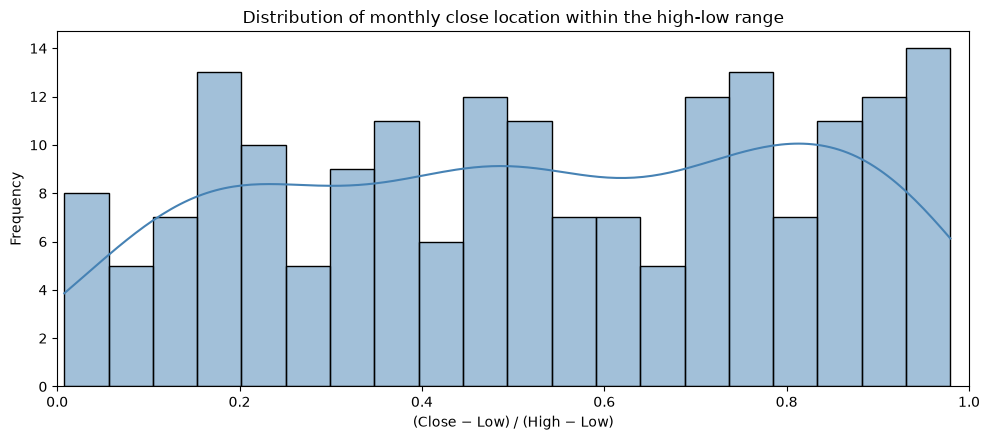

In [14]:
candle = df.copy()
candle['Close_Location'] = (candle['Close'] - candle['Low']) / (candle['High'] - candle['Low']).replace(0, np.nan)
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.histplot(candle['Close_Location'].dropna(), bins=20, kde=True, color='steelblue', ax=ax)
ax.set(xlim=(0,1), title='Distribution of monthly close location within the high-low range', xlabel='(Close − Low) / (High − Low)', ylabel='Frequency')
fig.tight_layout(); plt.show()

# 4. Hypothesis testing and time-series diagnostics

The tests below are descriptive diagnostics. Their p-values do not establish economic causality. The sample is short and contains a visibly changing price environment, so results should be interpreted with care.

## Hypothesis 1 — Is the log-price series stationary?

- **H₀:** The log closing-price series has a unit root (is non-stationary under the ADF test specification).
- **H₁:** The log closing-price series is stationary.
- **Test:** Augmented Dickey–Fuller (ADF), with an intercept and automatic lag selection.

In [15]:
adf_price = adfuller(np.log(df['Close']), autolag='AIC')
adf_return = adfuller(np.log(df['Close']).diff().dropna(), autolag='AIC')
adf_results = pd.DataFrame([
    {'Series':'Log Close','ADF statistic':adf_price[0],'p-value':adf_price[1],'used lags':adf_price[2]},
    {'Series':'Log Return','ADF statistic':adf_return[0],'p-value':adf_return[1],'used lags':adf_return[2]},
])
display(adf_results)
print('At 5% significance, reject H0 for log close:', bool(adf_price[1] < 0.05))
print('At 5% significance, reject H0 for log returns:', bool(adf_return[1] < 0.05))

,Series,ADF statistic,p-value,used lags
0,Log Close,-1.4333,0.5662,1
1,Log Return,-11.7391,0.0000,0


At 5% significance, reject H0 for log close: False
At 5% significance, reject H0 for log returns: True


**Test selection rationale:** The ADF test is a standard unit-root diagnostic. It is run on both log price and log returns because financial price levels may be non-stationary while returns are often closer to stationary. ADF power is limited in short samples and structural breaks can distort its result.

## Hypothesis 2 — Did absolute monthly return behaviour differ after 2017?

- **H₀:** The distribution of absolute monthly log returns is the same before 2018 and from 2018 onward.
- **H₁:** The distributions differ.
- **Test:** Two-sided Mann–Whitney U test, chosen because absolute returns are typically skewed and the two periods need not have equal variances. The grouping date is a descriptive breakpoint, not a claim about cause.

In [16]:
test_returns = eda.dropna(subset=['Log_Return']).copy()
pre = test_returns.loc[test_returns['Date'] < '2018-01-01', 'Log_Return'].abs()
post = test_returns.loc[test_returns['Date'] >= '2018-01-01', 'Log_Return'].abs()
if len(pre) < 5 or len(post) < 5:
    raise ValueError('Insufficient observations in one of the comparison periods.')
mw = mannwhitneyu(pre, post, alternative='two-sided')
print(f'Pre-2018 observations: {len(pre)} | 2018 onward: {len(post)}')
print(f'Median |return| pre-2018: {pre.median():.4f}')
print(f'Median |return| 2018 onward: {post.median():.4f}')
print(f'Mann–Whitney U: {mw.statistic:.2f} | p-value: {mw.pvalue:.6f}')
print('Decision at 5%:', 'Reject H0' if mw.pvalue < 0.05 else 'Fail to reject H0')

Pre-2018 observations: 149 | 2018 onward: 35
Median |return| pre-2018: 0.0698
Median |return| 2018 onward: 0.1271
Mann–Whitney U: 1616.00 | p-value: 0.000474
Decision at 5%: Reject H0


**Test selection rationale:** Mann–Whitney compares rank distributions without requiring normally distributed returns. A statistically significant result would show a distributional difference in absolute returns, not prove that a particular event caused it. The period split is exploratory and should be disclosed.

## Hypothesis 3 — Is there serial dependence in returns or squared returns?

- **H₀:** There is no autocorrelation through lag 12.
- **H₁:** At least one autocorrelation through lag 12 is non-zero.
- **Test:** Ljung–Box test, run separately on raw returns and squared returns.

In [17]:
lb_returns = acorr_ljungbox(returns, lags=[6, 12], return_df=True)
lb_squared = acorr_ljungbox(returns**2, lags=[6, 12], return_df=True)
print('Raw returns:')
display(lb_returns)
print('Squared returns:')
display(lb_squared)
print('Interpretation: low p-values for squared returns are consistent with volatility clustering.')

Raw returns:


,lb_stat,lb_pvalue
6,5.9724,0.4263
12,14.9559,0.2439


Squared returns:


,lb_stat,lb_pvalue
6,13.8926,0.0309
12,43.1475,0.0000


Interpretation: low p-values for squared returns are consistent with volatility clustering.


**Test selection rationale:** The Ljung–Box test jointly evaluates autocorrelation up to a specified lag. Running it on squared returns helps identify dependence in return magnitude. It is a diagnostic, not proof of a tradable pattern.

# 5. Feature engineering and preprocessing

## Forecast information set

For a forecast made after month *t* closes, the model may use that month's Open, High, Low and Close plus older observations. It may not use any fields from the future target month. The label for horizon *h* is:

\[
y_{t,h}=\log(Close_{t+h})-\log(Close_t)
\]

and the predicted price is reconstructed as:

\[
\widehat{Close}_{t+h}=Close_t\times\exp(\widehat y_{t,h})
\]

This target is more stable than fitting the raw price level and naturally supports multiple forecast horizons.

In [18]:
def build_feature_frame(data: pd.DataFrame) -> pd.DataFrame:
    """Create features known at each monthly close; never use future rows."""
    x = data.copy().sort_values('Date').reset_index(drop=True)
    close = x['Close'].astype(float)
    log_close = np.log(close)
    log_return = log_close.diff()
    prev_close = close.shift(1)

    features = pd.DataFrame(index=x.index)
    # Current candle information, available only after the month has closed.
    features['opening_gap_log'] = np.log(x['Open'] / prev_close)
    features['intramonth_body_log'] = np.log(x['Close'] / x['Open'])
    features['high_low_range_log'] = np.log(x['High'] / x['Low'])
    features['close_location'] = (x['Close'] - x['Low']) / (x['High'] - x['Low']).replace(0, np.nan)

    # Lagged return information: lag 1 is the return just completed at the current close.
    for lag in [1, 2, 3, 6, 9, 12]:
        features[f'return_lag_{lag}'] = log_return.shift(lag - 1)

    # Trailing return statistics and price momentum.
    for window in [3, 6, 12]:
        features[f'return_mean_{window}'] = log_return.rolling(window).mean()
        features[f'return_volatility_{window}'] = log_return.rolling(window).std()
        features[f'momentum_{window}'] = log_close - log_close.shift(window)
        features[f'close_vs_ma_{window}'] = close / close.rolling(window).mean() - 1

    # RSI-style indicators: exponentially weighted past gains/losses.
    delta = close.diff()
    gains = delta.clip(lower=0)
    losses = (-delta.clip(upper=0))
    for window in [6, 12]:
        avg_gain = gains.ewm(alpha=1/window, adjust=False, min_periods=window).mean()
        avg_loss = losses.ewm(alpha=1/window, adjust=False, min_periods=window).mean()
        rs = avg_gain / avg_loss.replace(0, np.nan)
        rsi = 100 - (100 / (1 + rs))
        # A zero average loss implies no losses in the lookback: define RSI as 100.
        rsi = rsi.where(avg_loss != 0, 100.0)
        features[f'rsi_{window}'] = rsi

    # Cyclical encoding avoids an artificial December-to-January distance.
    month = x['Date'].dt.month
    features['month_sin'] = np.sin(2 * np.pi * month / 12)
    features['month_cos'] = np.cos(2 * np.pi * month / 12)

    return features.replace([np.inf, -np.inf], np.nan)

features = build_feature_frame(df)
log_close = np.log(df['Close'])
feature_ok = features.notna().all(axis=1)
print('Feature matrix shape:', features.shape)
print('Usable rows after trailing-indicator warm-up:', int(feature_ok.sum()))
print('Engineered feature count:', features.shape[1])
display(features.loc[feature_ok].head(3))

Feature matrix shape: (185, 26)
Usable rows after trailing-indicator warm-up: 173
Engineered feature count: 26


,opening_gap_log,intramonth_body_log,high_low_range_log,close_location,return_lag_1,return_lag_2,return_lag_3,return_lag_6,return_lag_9,return_lag_12,return_mean_3,return_volatility_3,momentum_3,close_vs_ma_3,return_mean_6,return_volatility_6,momentum_6,close_vs_ma_6,return_mean_12,return_volatility_12,momentum_12,close_vs_ma_12,rsi_6,rsi_12,month_sin,month_cos
12,0.0240,0.0100,0.2188,0.6923,0.0340,-0.1435,-0.0779,0.0502,0.0318,0.0742,-0.0625,0.0897,-0.1874,-0.0267,0.0088,0.1257,0.0527,-0.0809,0.0217,0.0924,0.2600,0.0334,55.3392,70.1734,-0.5000,-0.8660
13,-0.0162,0.1151,0.1695,0.7379,0.0989,0.0340,-0.1435,0.2197,0.0221,-0.0090,-0.0035,0.1255,-0.0106,0.0786,0.0169,0.1304,0.1014,-0.0017,0.0237,0.0940,0.2847,0.1145,64.5970,73.6957,-0.8660,-0.5000
14,0.0089,0.0252,0.1167,0.7981,0.0342,0.0989,0.0340,-0.0298,0.1117,-0.0236,0.0557,0.0374,0.1671,0.0557,-0.0140,0.0877,-0.0841,0.0489,0.0273,0.0934,0.3278,0.1231,67.5737,74.8895,-1.0000,-0.0000


### Preprocessing decisions (mapped to the assignment template)

| Template item | Decision and justification |
|---|---|
| Missing values | No raw-field imputation is required after validation. Initial rows are missing only because lag/rolling indicators need history; those rows are excluded rather than filled with future information. |
| Outliers | Do not winsorize genuine market returns automatically. Extreme observations are inspected and retained; log-return targets reduce price-level scaling effects. |
| Categorical encoding | No high-cardinality categories exist. Month is encoded with sine/cosine to preserve circular calendar structure. |
| Text preprocessing | Not applicable: the dataset contains no free-text fields. |
| Feature manipulation | Lagged returns, momentum, rolling means/volatility, relative candle range, close location, RSI-style indicators and month cycles are created. |
| Feature selection | Compare regularized linear and tree ensembles; inspect time-held-out permutation importance. Importance is predictive, not causal. |
| Transformation | Log-return targets and log ratios are used to reduce dependence on the absolute price scale. |
| Scaling | StandardScaler is inside linear-model pipelines, so scaling is fitted within each CV training fold. Tree models do not require scaling. |
| Dimensionality reduction | PCA is not applied: the feature count is modest relative to the sample and preserving indicator meaning is preferable. |
| Data splitting | Chronological development/holdout split plus expanding-window CV with a horizon-aware gap. |
| Imbalance | Regression has no class imbalance. The optional direction classifier uses class weighting and is compared with a majority baseline. |

**No text cleaning, tokenization, lemmatization or text vectorization is performed** because there is no textual variable in the supplied dataset.

## Feature diagnostics

### Chart 11 — Engineered-feature correlation map

This diagnostic uses derived features rather than contemporaneous raw OHLC levels. It highlights redundant inputs that may affect linear-model stability.

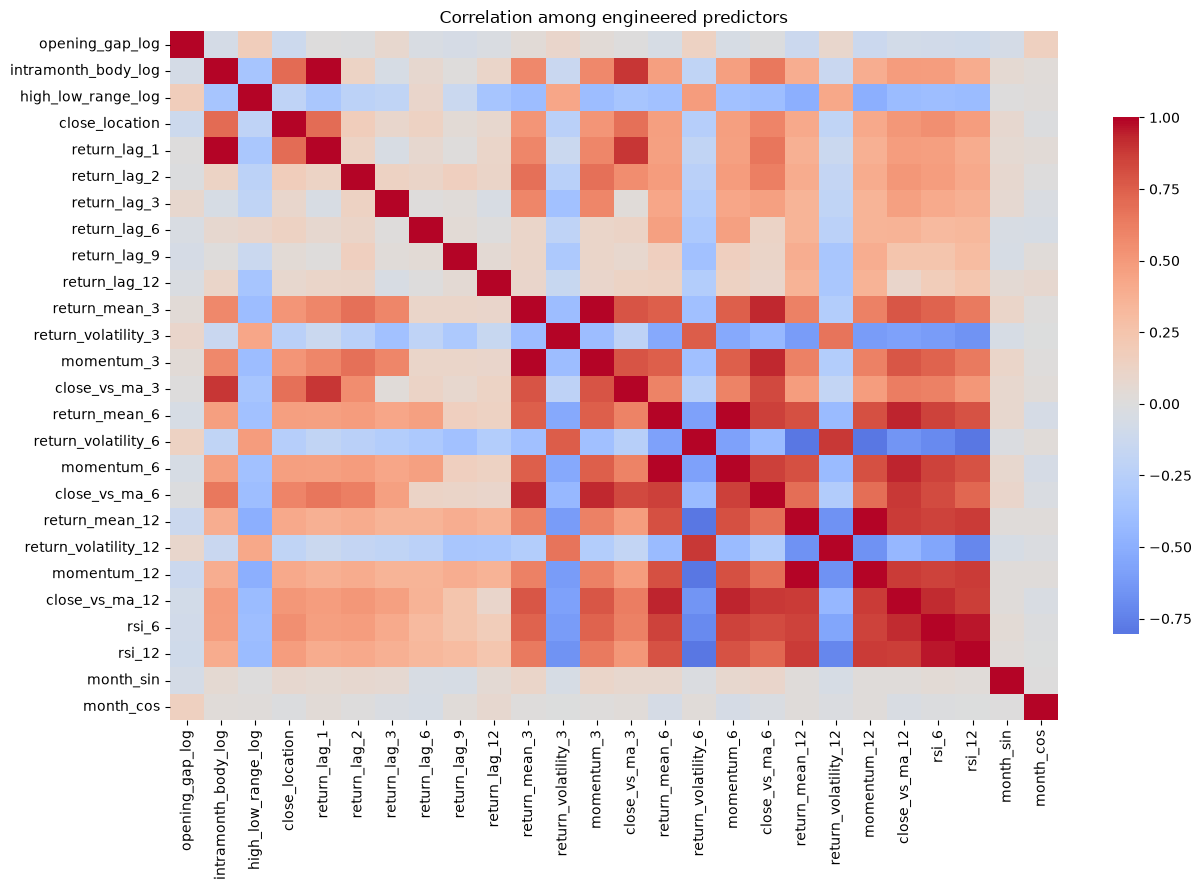

In [19]:
fig, ax = plt.subplots(figsize=(13, 9))
sns.heatmap(features.loc[feature_ok].corr(), cmap='coolwarm', center=0, ax=ax, cbar_kws={'shrink':.75})
ax.set_title('Correlation among engineered predictors')
fig.tight_layout(); plt.show()

### Chart 12 — Feature distributions

This chart checks scale and skew across engineered indicators. Scaling is applied only inside the relevant model pipeline; this plot is for inspection.

,mean,std,min,25%,50%,75%,max
opening_gap_log,0.0040,0.0123,-0.0414,-0.0004,0.0035,0.0089,0.0854
intramonth_body_log,-0.0044,0.1760,-0.7619,-0.0712,0.0119,0.0843,0.5172
high_low_range_log,0.2522,0.2507,0.0592,0.1377,0.1930,0.2855,2.7630
close_location,0.5341,0.2951,0.0078,0.2578,0.5495,0.7847,0.9795
return_lag_1,-0.0004,0.1756,-0.7619,-0.0595,0.0215,0.0843,0.5304
return_lag_2,-0.0022,0.1754,-0.7619,-0.0672,0.0207,0.0800,0.5304
return_lag_3,-0.0023,0.1755,-0.7619,-0.0689,0.0207,0.0800,0.5304
return_lag_6,0.0030,0.1658,-0.6270,-0.0595,0.0215,0.0800,0.5304
return_lag_9,0.0032,0.1651,-0.6270,-0.0595,0.0221,0.0800,0.5304
return_lag_12,0.0077,0.1609,-0.6270,-0.0550,0.0248,0.0800,0.5304


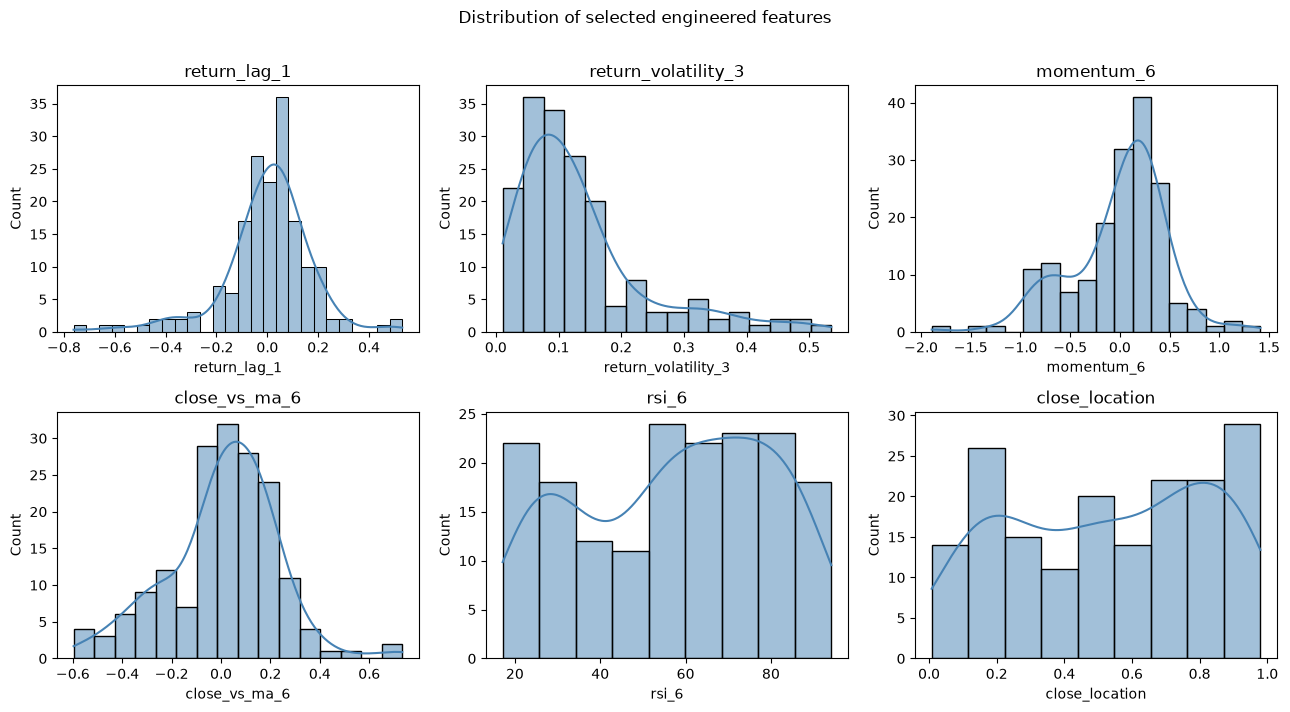

In [20]:
display(features.loc[feature_ok].describe().T[['mean','std','min','25%','50%','75%','max']])
selected_dist = ['return_lag_1','return_volatility_3','momentum_6','close_vs_ma_6','rsi_6','close_location']
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(axes.flat, selected_dist):
    sns.histplot(features.loc[feature_ok, col], kde=True, color='steelblue', ax=ax)
    ax.set_title(col)
fig.suptitle('Distribution of selected engineered features', y=1.01)
fig.tight_layout(); plt.show()

# 6. Time-aware split and benchmark forecasts

A single final 20% of forecast origins is reserved as the chronological holdout. For horizon *h*, a training label is considered observable at forecast origin *t* only when its target date is no later than *t*. During tuning, `TimeSeriesSplit(gap=h)` adds a horizon-sized gap so a training label cannot extend into its validation forecast period.

In [21]:
HORIZONS = [1, 3, 6]
TEST_FRACTION = 0.20
N = len(df)
HOLDOUT_START = int(np.floor(N * (1 - TEST_FRACTION)))
valid_origins = np.flatnonzero(feature_ok.to_numpy())

print(f'Final holdout forecast origins start at row {HOLDOUT_START} ({df.loc[HOLDOUT_START, "Date"]:%b-%Y}).')
print(f'Total rows: {N}; initial history before holdout: {HOLDOUT_START}.')

# Prepare horizon-specific future log-return targets. A row's target index is origin + horizon.
targets = {}
for h in HORIZONS:
    targets[h] = log_close.shift(-h) - log_close

# The number of labelled rows varies by horizon because a future close is required.
for h in HORIZONS:
    labelled = feature_ok & targets[h].notna()
    train_n = int((labelled & ((np.arange(N) + h) <= HOLDOUT_START)).sum())
    test_n = int((labelled & (np.arange(N) >= HOLDOUT_START)).sum())
    print(f'{h}-month horizon | usable labels: {int(labelled.sum())} | mature pre-holdout train labels: {train_n} | holdout origins: {test_n}')

Final holdout forecast origins start at row 148 (Nov-2017).
Total rows: 185; initial history before holdout: 148.
1-month horizon | usable labels: 172 | mature pre-holdout train labels: 136 | holdout origins: 36
3-month horizon | usable labels: 170 | mature pre-holdout train labels: 134 | holdout origins: 34
6-month horizon | usable labels: 167 | mature pre-holdout train labels: 131 | holdout origins: 31


## Baseline definitions

- **Persistence:** predict zero future log return, so the future close equals the latest known close.
- **Expanding drift:** predict the mean future log return from all labels mature by the current forecast origin.
- **Seasonal naïve:** predict the close from the same calendar month one year earlier. This is valid for the 1-, 3- and 6-month horizons because the comparable month is already observed in the history.
- **ARIMA(1,1,0):** fit a fixed autoregressive integrated model to the log closing-price level at each forecast origin and predict the requested horizon. The order is pre-specified as a transparent statistical comparator, not selected on the holdout. Numerical fit failures are recorded and fall back explicitly to persistence.

A machine-learning model must be compared with these simple alternatives. If it cannot demonstrate incremental value, it should not be presented as the preferred forecasting solution.

# 7. ML model implementation: time-series CV and tuning

Five candidate machine-learning families are included, alongside a fixed ARIMA(1,1,0) statistical benchmark: Ridge, Elastic Net, Random Forest, Extra Trees and histogram gradient boosting. Linear models are scaled inside a pipeline. Tree models are deliberately kept shallow / regularized because 185 monthly observations are not enough to support an unconstrained high-capacity model.

In [22]:
from sklearn.base import BaseEstimator

MODEL_SPECS = {
    'Ridge': (
        Pipeline([('scaler', StandardScaler()), ('model', Ridge())]),
        {'model__alpha': [0.1, 1.0, 10.0, 100.0]}
    ),
    'Elastic Net': (
        Pipeline([('scaler', StandardScaler()), ('model', ElasticNet(max_iter=20000, random_state=RANDOM_STATE))]),
        {'model__alpha': [0.01, 0.1], 'model__l1_ratio': [0.25, 0.75]}
    ),
    'Random Forest': (
        RandomForestRegressor(n_estimators=60, random_state=RANDOM_STATE, n_jobs=1),
        {'max_depth': [2, 3], 'min_samples_leaf': [4, 8]}
    ),
    'Extra Trees': (
        ExtraTreesRegressor(n_estimators=60, random_state=RANDOM_STATE, n_jobs=1),
        {'max_depth': [2, 3], 'min_samples_leaf': [4, 8]}
    ),
    'Hist Gradient Boosting': (
        HistGradientBoostingRegressor(max_iter=100, random_state=RANDOM_STATE, early_stopping=False),
        {'learning_rate': [0.03, 0.08], 'max_leaf_nodes': [5, 10]}
    ),
}


def tune_regressors_for_horizon(horizon: int):
    """Tune on pre-holdout matured targets using expanding CV and a horizon gap."""
    y_all = targets[horizon]
    origins = np.flatnonzero(feature_ok.to_numpy() & y_all.notna().to_numpy())
    train_origins = origins[(origins + horizon) <= HOLDOUT_START]
    X_train = features.iloc[train_origins].copy()
    y_train = y_all.iloc[train_origins].copy()
    if len(X_train) < 50:
        raise ValueError(f'Not enough pre-holdout labelled samples for horizon {horizon}.')

    splitter = TimeSeriesSplit(n_splits=3, gap=horizon)
    rows = []
    best = None
    for model_name, (base_estimator, grid) in MODEL_SPECS.items():
        for params in ParameterGrid(grid):
            fold_scores = []
            for train_idx, val_idx in splitter.split(X_train):
                estimator = clone(base_estimator).set_params(**params)
                estimator.fit(X_train.iloc[train_idx], y_train.iloc[train_idx])
                prediction = estimator.predict(X_train.iloc[val_idx])
                fold_scores.append(mean_absolute_error(y_train.iloc[val_idx], prediction))
            score = float(np.mean(fold_scores))
            row = {'Horizon': horizon, 'Model': model_name, 'CV_MAE_LogReturn': score,
                   'Fold_MAE_Std': float(np.std(fold_scores)), 'Parameters': params}
            rows.append(row)
            if best is None or score < best['CV_MAE_LogReturn']:
                best = row.copy()

    best_estimator = clone(MODEL_SPECS[best['Model']][0]).set_params(**best['Parameters'])
    tuning_table = pd.DataFrame(rows).sort_values('CV_MAE_LogReturn').reset_index(drop=True)
    return best, best_estimator, X_train, y_train, splitter, tuning_table

best_by_horizon = {}
selected_estimators = {}
training_sets = {}
cv_splits = {}
tuning_tables = {}

for h in HORIZONS:
    best, estimator, X_train, y_train, splitter, table = tune_regressors_for_horizon(h)
    best_by_horizon[h] = best
    selected_estimators[h] = estimator
    training_sets[h] = (X_train, y_train)
    cv_splits[h] = splitter
    tuning_tables[h] = table
    print(f"Horizon {h}m | selected: {best['Model']} | CV MAE (log-return): {best['CV_MAE_LogReturn']:.5f} | params: {best['Parameters']}")

all_tuning_results = pd.concat(tuning_tables.values(), ignore_index=True)
display(all_tuning_results.sort_values(['Horizon','CV_MAE_LogReturn']).groupby('Horizon').head(8))

Horizon 1m | selected: Extra Trees | CV MAE (log-return): 0.08705 | params: {'max_depth': 3, 'min_samples_leaf': 8}
Horizon 3m | selected: Elastic Net | CV MAE (log-return): 0.15328 | params: {'model__alpha': 0.1, 'model__l1_ratio': 0.75}
Horizon 6m | selected: Elastic Net | CV MAE (log-return): 0.20094 | params: {'model__alpha': 0.1, 'model__l1_ratio': 0.75}


,Horizon,Model,CV_MAE_LogReturn,Fold_MAE_Std,Parameters
0,1,Extra Trees,0.0871,0.0154,"{'max_depth': 3, 'min_samples_leaf': 8}"
1,1,Extra Trees,0.0872,0.0164,"{'max_depth': 2, 'min_samples_leaf': 8}"
2,1,Elastic Net,0.0883,0.0149,"{'model__alpha': 0.1, 'model__l1_ratio': 0.75}"
3,1,Ridge,0.0890,0.0160,{'model__alpha': 100.0}
4,1,Random Forest,0.0890,0.0122,"{'max_depth': 2, 'min_samples_leaf': 8}"
5,1,Extra Trees,0.0899,0.0162,"{'max_depth': 2, 'min_samples_leaf': 4}"
6,1,Hist Gradient Boosting,0.0899,0.0175,"{'learning_rate': 0.03, 'max_leaf_nodes': 10}"
7,1,Hist Gradient Boosting,0.0899,0.0175,"{'learning_rate': 0.03, 'max_leaf_nodes': 5}"
20,3,Elastic Net,0.1533,0.0261,"{'model__alpha': 0.1, 'model__l1_ratio': 0.75}"
21,3,Random Forest,0.1592,0.0403,"{'max_depth': 2, 'min_samples_leaf': 4}"


Horizon 6m | selected: Elastic Net | CV MAE (log-return): 0.20094 | params: {'model__alpha': 0.1, 'model__l1_ratio': 0.75}


,Horizon,Model,CV_MAE_LogReturn,Fold_MAE_Std,Parameters
0,1,Extra Trees,0.0871,0.0154,"{'max_depth': 3, 'min_samples_leaf': 8}"
1,1,Extra Trees,0.0872,0.0164,"{'max_depth': 2, 'min_samples_leaf': 8}"
2,1,Elastic Net,0.0883,0.0149,"{'model__alpha': 0.1, 'model__l1_ratio': 0.75}"
3,1,Ridge,0.0890,0.0160,{'model__alpha': 100.0}
4,1,Random Forest,0.0890,0.0122,"{'max_depth': 2, 'min_samples_leaf': 8}"
5,1,Extra Trees,0.0899,0.0162,"{'max_depth': 2, 'min_samples_leaf': 4}"
6,1,Hist Gradient Boosting,0.0899,0.0175,"{'learning_rate': 0.03, 'max_leaf_nodes': 10}"
7,1,Hist Gradient Boosting,0.0899,0.0175,"{'learning_rate': 0.03, 'max_leaf_nodes': 5}"
20,3,Elastic Net,0.1533,0.0261,"{'model__alpha': 0.1, 'model__l1_ratio': 0.75}"
21,3,Random Forest,0.1592,0.0403,"{'max_depth': 2, 'min_samples_leaf': 4}"


### Chart 13 — Cross-validation model comparison

The chart compares the candidate model families using only expanding-window CV inside the development period. It is not the final holdout score.

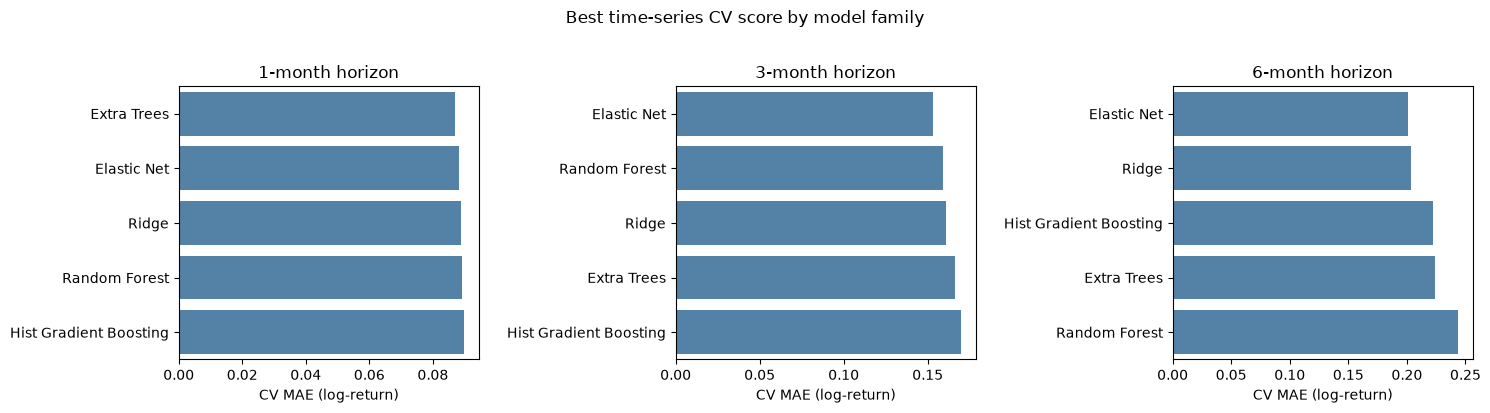

In [23]:
cv_plot = all_tuning_results.groupby(['Horizon','Model'])['CV_MAE_LogReturn'].min().reset_index()
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=False)
for ax, h in zip(axes, HORIZONS):
    dplot = cv_plot[cv_plot['Horizon'] == h].sort_values('CV_MAE_LogReturn')
    sns.barplot(data=dplot, x='CV_MAE_LogReturn', y='Model', color='steelblue', ax=ax)
    ax.set_title(f'{h}-month horizon')
    ax.set_xlabel('CV MAE (log-return)')
    ax.set_ylabel('')
fig.suptitle('Best time-series CV score by model family', y=1.02)
fig.tight_layout(); plt.show()

### Chart 28 — Feature-ablation experiment: does engineering add value?

A disciplined feature-ablation test compares a small lag-only information set with progressively richer indicators. The same standardized Ridge estimator and the same time-series CV folds are used for every group; the final holdout is not used in this experiment. This tests whether added complexity improves training-period out-of-time validation rather than assuming that more features are automatically better.

,Feature_Set,Feature_Count,CV_MAE_LogReturn,Fold_MAE_Std
0,Last return only,1,0.0866,0.0152
2,Lag + rolling / momentum,18,0.0945,0.0140
1,Lagged returns,6,0.0963,0.0178
3,All engineered features,26,0.1034,0.0195


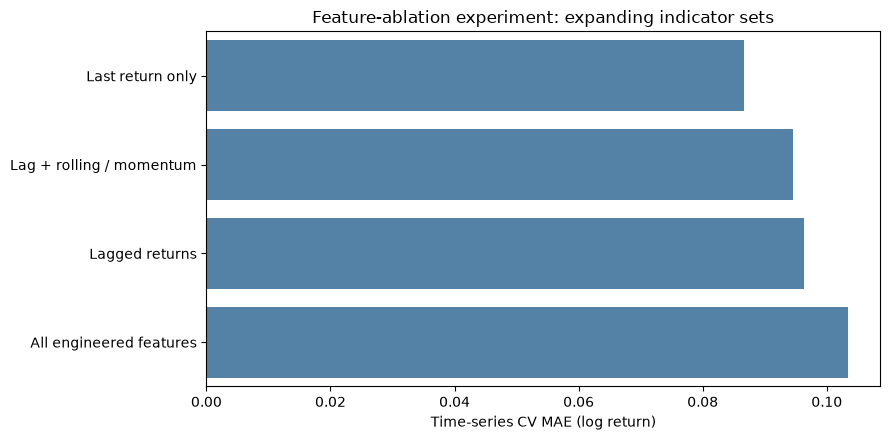

In [24]:
# Compare feature groups with the same estimator and exactly the same CV folds.
X_ablation, y_ablation = training_sets[1]
feature_groups = {
    'Last return only': ['return_lag_1'],
    'Lagged returns': [c for c in features.columns if c.startswith('return_lag_')],
    'Lag + rolling / momentum': [c for c in features.columns if c.startswith(('return_lag_', 'return_mean_', 'return_volatility_', 'momentum_', 'close_vs_ma_'))],
    'All engineered features': features.columns.tolist(),
}

ablation_rows = []
for group_name, cols in feature_groups.items():
    fold_maes = []
    for tr_idx, va_idx in cv_splits[1].split(X_ablation):
        ablation_model = Pipeline([
            ('scaler', StandardScaler()),
            ('model', Ridge(alpha=10.0))
        ])
        ablation_model.fit(X_ablation.iloc[tr_idx][cols], y_ablation.iloc[tr_idx])
        pred = ablation_model.predict(X_ablation.iloc[va_idx][cols])
        fold_maes.append(mean_absolute_error(y_ablation.iloc[va_idx], pred))
    ablation_rows.append({
        'Feature_Set': group_name,
        'Feature_Count': len(cols),
        'CV_MAE_LogReturn': float(np.mean(fold_maes)),
        'Fold_MAE_Std': float(np.std(fold_maes)),
    })

ablation_results = pd.DataFrame(ablation_rows).sort_values('CV_MAE_LogReturn')
display(ablation_results)
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=ablation_results, x='CV_MAE_LogReturn', y='Feature_Set', color='steelblue', ax=ax)
ax.set(title='Feature-ablation experiment: expanding indicator sets', xlabel='Time-series CV MAE (log return)', ylabel='')
fig.tight_layout(); plt.show()

## Walk-forward holdout forecasting

For every test forecast origin, the selected model is retrained using only rows whose target month has already arrived. This is especially important for 3- and 6-month targets: a label from a forecast made recently is not available until its future target date has passed.

In [25]:
def regression_metrics(actual_price, predicted_price, actual_log_return, predicted_log_return):
    actual_price = np.asarray(actual_price, dtype=float)
    predicted_price = np.asarray(predicted_price, dtype=float)
    actual_log_return = np.asarray(actual_log_return, dtype=float)
    predicted_log_return = np.asarray(predicted_log_return, dtype=float)
    mae = mean_absolute_error(actual_price, predicted_price)
    rmse = float(np.sqrt(mean_squared_error(actual_price, predicted_price)))
    mape = float(np.mean(np.abs((actual_price - predicted_price) / actual_price)) * 100)
    smape = float(np.mean(2 * np.abs(actual_price - predicted_price) /
                           (np.abs(actual_price) + np.abs(predicted_price))) * 100)
    return {
        'MAE_Rupees': mae,
        'RMSE_Rupees': rmse,
        'MAPE_pct': mape,
        'sMAPE_pct': smape,
        'MAE_LogReturn': mean_absolute_error(actual_log_return, predicted_log_return),
        'Direction_Accuracy_pct': float(np.mean(np.sign(actual_log_return) == np.sign(predicted_log_return)) * 100),
        'R2_Price': r2_score(actual_price, predicted_price) if len(actual_price) > 1 else np.nan,
    }

walk_forward_results = {}
cv_residuals = {}
last_fitted_models = {}

for h in HORIZONS:
    y_all = targets[h]
    origins = np.flatnonzero(feature_ok.to_numpy() & y_all.notna().to_numpy())
    test_origins = origins[(origins >= HOLDOUT_START)]
    selected_model = selected_estimators[h]

    records = []
    last_model = None
    for origin in test_origins:
        # A training label is mature only if its target index is at or before this origin.
        mature_origins = origins[(origins + h) <= origin]
        X_hist = features.iloc[mature_origins]
        y_hist = y_all.iloc[mature_origins]
        if len(X_hist) < 40:
            continue
        fitted = clone(selected_model)
        fitted.fit(X_hist, y_hist)
        predicted_log_return = float(fitted.predict(features.iloc[[origin]])[0])

        # Transparent benchmarks use only information available at the forecast origin.
        persistence_log_return = 0.0
        drift_log_return = float(y_hist.mean())
        seasonal_target_idx = origin + h - 12
        seasonal_price = float(df.loc[seasonal_target_idx, 'Close']) if seasonal_target_idx >= 0 else np.nan
        seasonal_log_return = (float(np.log(seasonal_price / df.loc[origin, 'Close']))
                               if np.isfinite(seasonal_price) else np.nan)

        # Fixed, pre-specified ARIMA(1,1,0) statistical benchmark on log close.
        # Refit at each origin using only observations available by that date.
        arima_log_return = 0.0
        arima_fit_status = 'ok'
        try:
            with warnings.catch_warnings():
                warnings.simplefilter('ignore')
                arima_fit = ARIMA(
                    log_close.iloc[:origin + 1], order=(1, 1, 0), trend='n'
                ).fit()
                arima_forecast_log_close = float(np.asarray(arima_fit.forecast(steps=h))[-1])
            arima_log_return = arima_forecast_log_close - float(log_close.iloc[origin])
        except Exception as exc:
            # Explicit fallback preserves the forecast record if a numerical fit fails.
            arima_fit_status = f'fallback_persistence: {type(exc).__name__}'
            arima_log_return = 0.0

        anchor = float(df.loc[origin, 'Close'])
        target_idx = origin + h
        actual_price = float(df.loc[target_idx, 'Close'])
        actual_log_return = float(y_all.iloc[origin])
        records.append({
            'Horizon': h, 'Origin_Index': int(origin), 'Origin_Date': df.loc[origin, 'Date'],
            'Target_Date': df.loc[target_idx, 'Date'], 'Anchor_Close': anchor,
            'Actual_Close': actual_price, 'Actual_LogReturn': actual_log_return,
            'ML_LogReturn': predicted_log_return,
            'ML_Predicted_Close': anchor * np.exp(predicted_log_return),
            'Persistence_LogReturn': persistence_log_return,
            'Persistence_Predicted_Close': anchor,
            'Drift_LogReturn': drift_log_return,
            'Drift_Predicted_Close': anchor * np.exp(drift_log_return),
            'Seasonal_LogReturn': seasonal_log_return,
            'Seasonal_Predicted_Close': seasonal_price,
            'ARIMA_LogReturn': arima_log_return,
            'ARIMA_Predicted_Close': anchor * np.exp(arima_log_return),
            'ARIMA_Fit_Status': arima_fit_status,
        })
        last_model = fitted

    result = pd.DataFrame(records)
    if result.empty:
        raise RuntimeError(f'No walk-forward forecasts generated for horizon {h}.')
    walk_forward_results[h] = result
    last_fitted_models[h] = last_model

    # Generate strictly out-of-fold residuals from the same pre-holdout CV scheme for interval calibration.
    X_train, y_train = training_sets[h]
    residual_parts = []
    for tr_idx, va_idx in cv_splits[h].split(X_train):
        fold_model = clone(selected_model)
        fold_model.fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
        fold_pred = fold_model.predict(X_train.iloc[va_idx])
        residual_parts.extend((y_train.iloc[va_idx].to_numpy() - fold_pred).tolist())
    cv_residuals[h] = np.asarray(residual_parts, dtype=float)

print('Walk-forward forecasts created. Example (1-month horizon):')
display(walk_forward_results[1].head())

Walk-forward forecasts created. Example (1-month horizon):


,Horizon,Origin_Index,Origin_Date,Target_Date,Anchor_Close,Actual_Close,Actual_LogReturn,ML_LogReturn,ML_Predicted_Close,Persistence_LogReturn,Persistence_Predicted_Close,Drift_LogReturn,Drift_Predicted_Close,Seasonal_LogReturn,Seasonal_Predicted_Close,ARIMA_LogReturn,ARIMA_Predicted_Close,ARIMA_Fit_Status
0,1,148,2017-11-01,2017-12-01,306.8000,315.0500,0.0265,0.0308,316.3897,0.0000,306.8000,0.0216,313.5129,-0.2827,231.2600,-0.0057,305.0580,ok
1,1,149,2017-12-01,2018-01-01,315.0500,354.4500,0.1178,0.0272,323.7372,0.0000,315.0500,0.0217,321.9549,-0.1212,279.1000,0.0062,317.0119,ok
2,1,150,2018-01-01,2018-02-01,354.4500,322.2500,-0.0952,0.0183,360.9920,0.0000,354.4500,0.0224,362.4709,-0.1988,290.5600,0.0277,364.4029,ok
3,1,151,2018-02-01,2018-03-01,322.2500,304.9000,-0.0553,-0.0209,315.5897,0.0000,322.2500,0.0215,329.2636,-0.0393,309.8200,-0.0219,315.2712,ok
4,1,152,2018-03-01,2018-04-01,304.9000,362.0500,0.1718,0.0178,310.3883,0.0000,304.9000,0.0210,311.3649,0.0673,326.1400,-0.0128,301.0265,ok


## Holdout model scorecards

The following table evaluates the walk-forward machine-learning prediction and all naïve baselines plus the fixed ARIMA statistical benchmark on identical target dates. The model family for each horizon was selected using training-only CV.

In [26]:
metric_rows = []
for h, result in walk_forward_results.items():
    metric_rows.append({'Horizon':h, 'Forecast':'Selected ML: ' + best_by_horizon[h]['Model'],
                        **regression_metrics(result['Actual_Close'], result['ML_Predicted_Close'],
                                             result['Actual_LogReturn'], result['ML_LogReturn'])})
    for label, pred_col, ret_col in [
        ('Persistence', 'Persistence_Predicted_Close', 'Persistence_LogReturn'),
        ('Expanding drift', 'Drift_Predicted_Close', 'Drift_LogReturn'),
        ('Seasonal naive', 'Seasonal_Predicted_Close', 'Seasonal_LogReturn'),
        ('ARIMA(1,1,0)', 'ARIMA_Predicted_Close', 'ARIMA_LogReturn')]:
        valid = result[[pred_col, ret_col]].notna().all(axis=1)
        if valid.any():
            metric_rows.append({'Horizon':h, 'Forecast':label,
                                **regression_metrics(result.loc[valid,'Actual_Close'], result.loc[valid,pred_col],
                                                     result.loc[valid,'Actual_LogReturn'], result.loc[valid,ret_col])})

holdout_metrics = pd.DataFrame(metric_rows)
display(holdout_metrics.sort_values(['Horizon','MAE_Rupees']))

,Horizon,Forecast,MAE_Rupees,RMSE_Rupees,MAPE_pct,sMAPE_pct,MAE_LogReturn,Direction_Accuracy_pct,R2_Price
1,1,Persistence,23.7964,38.8216,22.4614,19.2910,0.1958,0.0000,0.9072
0,1,Selected ML: Extra Trees,24.2954,40.5154,22.6502,19.9379,0.2024,52.7778,0.8989
2,1,Expanding drift,24.3628,40.0808,22.9769,19.5448,0.1985,36.1111,0.9011
4,1,"ARIMA(1,1,0)",24.4651,39.4639,22.5775,19.9215,0.2023,52.7778,0.9041
3,1,Seasonal naive,113.5900,136.3138,225.8030,80.0856,0.9432,44.4444,-0.1442
6,3,Persistence,43.2294,68.4314,51.1973,35.4576,0.3682,0.0000,0.6904
9,3,"ARIMA(1,1,0)",45.0690,69.5413,52.3690,37.2218,0.3857,55.8824,0.6803
7,3,Expanding drift,47.2030,75.4402,54.7695,36.8652,0.3842,35.2941,0.6237
5,3,Selected ML: Elastic Net,47.4200,75.7852,55.1358,37.1046,0.3867,32.3529,0.6203
8,3,Seasonal naive,115.5912,138.9281,237.6781,83.1947,0.9825,32.3529,-0.2761


### Chart 14 — Holdout MAE by horizon and benchmark

A price-level MAE chart makes the cost of forecast errors interpretable in rupees. Comparisons should be made within the same horizon; longer horizons naturally have different difficulty.

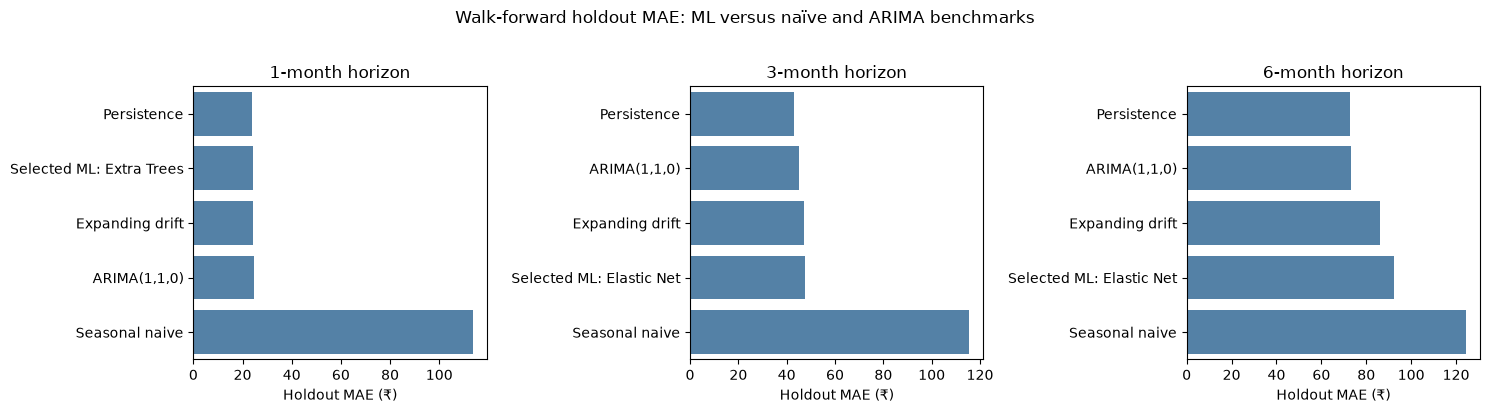

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, h in zip(axes, HORIZONS):
    p = holdout_metrics[holdout_metrics['Horizon'] == h].sort_values('MAE_Rupees')
    sns.barplot(data=p, x='MAE_Rupees', y='Forecast', color='steelblue', ax=ax)
    ax.set_title(f'{h}-month horizon')
    ax.set_xlabel('Holdout MAE (₹)')
    ax.set_ylabel('')
fig.suptitle('Walk-forward holdout MAE: ML versus naïve and ARIMA benchmarks', y=1.02)
fig.tight_layout(); plt.show()

### Chart 15 — Actual versus forecast path for each horizon

This plot shows the forecast value at each origin against the realized target close. The x-axis is the forecast origin, while the target occurs 1, 3 or 6 months later.

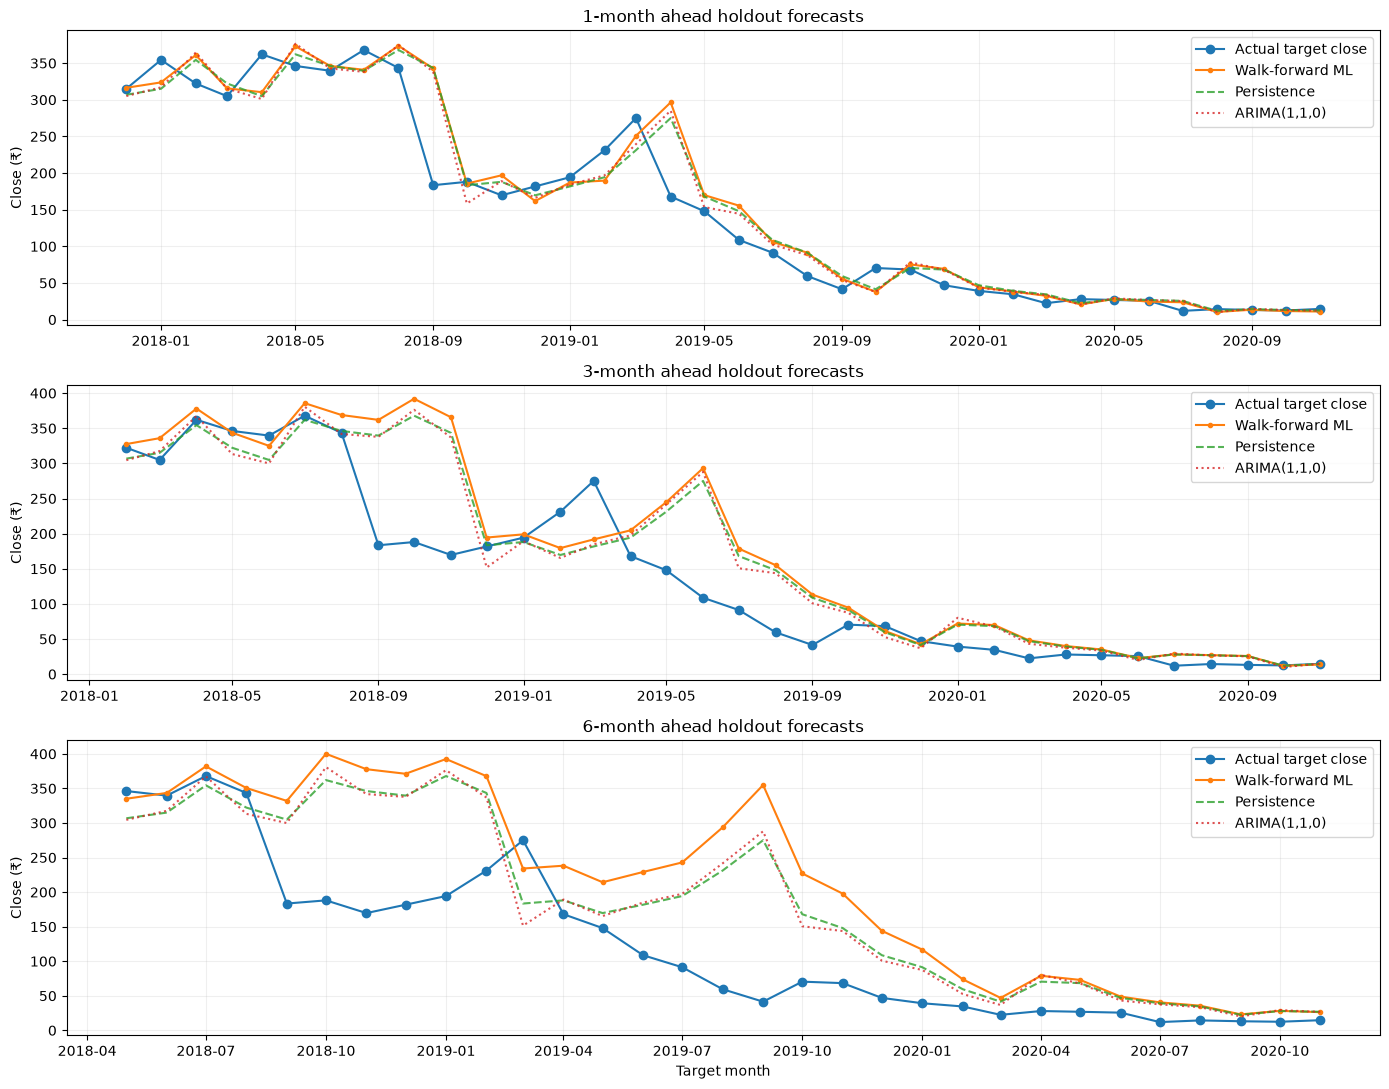

In [28]:
fig, axes = plt.subplots(3, 1, figsize=(14, 11))
for ax, h in zip(axes, HORIZONS):
    r = walk_forward_results[h]
    ax.plot(r['Target_Date'], r['Actual_Close'], marker='o', label='Actual target close')
    ax.plot(r['Target_Date'], r['ML_Predicted_Close'], marker='.', label='Walk-forward ML')
    ax.plot(r['Target_Date'], r['Persistence_Predicted_Close'], linestyle='--', alpha=.8, label='Persistence')
    ax.plot(r['Target_Date'], r['ARIMA_Predicted_Close'], linestyle=':', alpha=.8, label='ARIMA(1,1,0)')
    ax.set_title(f'{h}-month ahead holdout forecasts')
    ax.set_ylabel('Close (₹)'); ax.grid(alpha=.2); ax.legend()
axes[-1].set_xlabel('Target month')
fig.tight_layout(); plt.show()

### Chart 16 — Predicted versus actual closing prices

A scatter plot near the 45-degree line indicates accurate price-level predictions. A systematic bias above or below the line indicates over- or under-prediction.

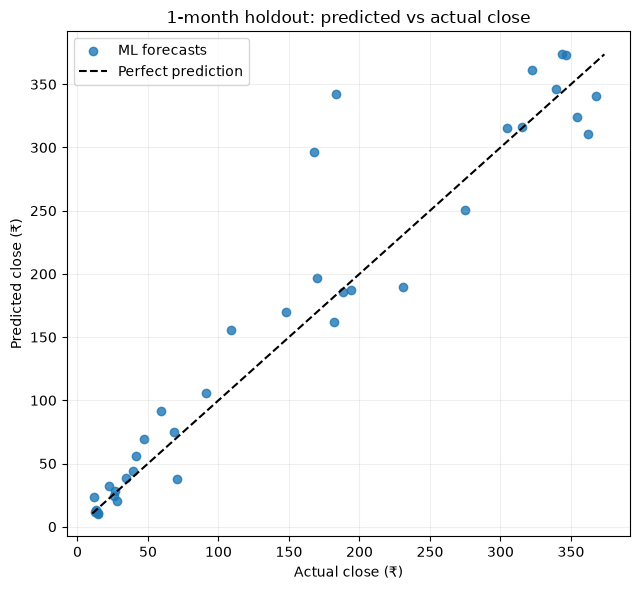

In [29]:
r1 = walk_forward_results[1]
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(r1['Actual_Close'], r1['ML_Predicted_Close'], alpha=.8, label='ML forecasts')
lo = min(r1['Actual_Close'].min(), r1['ML_Predicted_Close'].min())
hi = max(r1['Actual_Close'].max(), r1['ML_Predicted_Close'].max())
ax.plot([lo,hi],[lo,hi], color='black', linestyle='--', label='Perfect prediction')
ax.set(title='1-month holdout: predicted vs actual close', xlabel='Actual close (₹)', ylabel='Predicted close (₹)')
ax.legend(); ax.grid(alpha=.2); fig.tight_layout(); plt.show()

# 8. Secondary experiment: next-month direction classification

The classifier predicts whether the next monthly close is higher than the current close. It is deliberately secondary: 185 monthly observations provide limited statistical power, and direction accuracy does not measure the size of gains or losses. Results are compared with a majority-class benchmark.

In [30]:
# Direction target: 1 means next-month close is higher; 0 means flat or lower.
h = 1
y_direction = (targets[h] > 0).astype(float)
valid_dir = feature_ok & targets[h].notna()
origin_dir = np.flatnonzero(valid_dir.to_numpy())
train_dir = origin_dir[(origin_dir + 1) <= HOLDOUT_START]
X_dir = features.iloc[train_dir]
y_dir = y_direction.iloc[train_dir].astype(int)

classifier_specs = {
    'Logistic Regression': (
        Pipeline([('scaler', StandardScaler()), ('model', LogisticRegression(class_weight='balanced', max_iter=5000, random_state=RANDOM_STATE))]),
        {'model__C':[0.01,0.1,1,10,100]}
    ),
    'Shallow Decision Tree': (
        DecisionTreeClassifier(class_weight='balanced', random_state=RANDOM_STATE),
        {'max_depth':[2,3], 'min_samples_leaf':[5,10]}
    ),
}

def tune_classifier(X, y, gap=1):
    splitter = TimeSeriesSplit(n_splits=3, gap=gap)
    scores = []
    for name, (base, grid) in classifier_specs.items():
        for params in ParameterGrid(grid):
            fold_scores = []
            for tr, va in splitter.split(X):
                model = clone(base).set_params(**params)
                model.fit(X.iloc[tr], y.iloc[tr])
                pred = model.predict(X.iloc[va])
                fold_scores.append(balanced_accuracy_score(y.iloc[va], pred))
            scores.append({'Model':name,'CV_Balanced_Accuracy':float(np.mean(fold_scores)),
                           'Fold_Std':float(np.std(fold_scores)),'Parameters':params})
    table = pd.DataFrame(scores).sort_values('CV_Balanced_Accuracy', ascending=False).reset_index(drop=True)
    winner = table.iloc[0]
    base = classifier_specs[winner['Model']][0]
    return table, winner['Model'], clone(base).set_params(**winner['Parameters'])

classifier_cv, best_classifier_name, best_classifier = tune_classifier(X_dir, y_dir)
print('Class balance in development sample:', y_dir.value_counts(normalize=True).sort_index().to_dict())
print('Selected direction model by training-only CV:', best_classifier_name)
display(classifier_cv.head(8))

Class balance in development sample: {0: 0.40441176470588236, 1: 0.5955882352941176}
Selected direction model by training-only CV: Shallow Decision Tree


,Model,CV_Balanced_Accuracy,Fold_Std,Parameters
0,Shallow Decision Tree,0.6042,0.0219,"{'max_depth': 2, 'min_samples_leaf': 10}"
1,Shallow Decision Tree,0.5937,0.0390,"{'max_depth': 2, 'min_samples_leaf': 5}"
2,Shallow Decision Tree,0.5626,0.0403,"{'max_depth': 3, 'min_samples_leaf': 10}"
3,Logistic Regression,0.5485,0.0226,{'model__C': 0.01}
4,Logistic Regression,0.5193,0.0261,{'model__C': 0.1}
5,Shallow Decision Tree,0.5019,0.0519,"{'max_depth': 3, 'min_samples_leaf': 5}"
6,Logistic Regression,0.4724,0.0280,{'model__C': 1}
7,Logistic Regression,0.4597,0.0434,{'model__C': 100}


### Walk-forward direction probabilities

The classifier is refitted at each forecast origin using only matured next-month labels. Probability outputs are experimental rankings; calibration and stability are checked below.

In [31]:
direction_records = []
for origin in origin_dir[origin_dir >= HOLDOUT_START]:
    mature = origin_dir[(origin_dir + 1) <= origin]
    model = clone(best_classifier)
    model.fit(features.iloc[mature], y_direction.iloc[mature].astype(int))
    probability_up = float(model.predict_proba(features.iloc[[origin]])[0, 1])
    prediction_up = int(probability_up >= 0.5)
    direction_records.append({
        'Origin_Index':int(origin), 'Origin_Date':df.loc[origin,'Date'],
        'Target_Date':df.loc[origin+1,'Date'], 'Actual_Up':int(y_direction.iloc[origin]),
        'Probability_Up':probability_up, 'Predicted_Up':prediction_up,
    })
direction_test = pd.DataFrame(direction_records)
actual_dir = direction_test['Actual_Up']
pred_dir = direction_test['Predicted_Up']
prob_dir = direction_test['Probability_Up']
direction_summary = {
    'Accuracy':accuracy_score(actual_dir,pred_dir),
    'Balanced accuracy':balanced_accuracy_score(actual_dir,pred_dir),
    'Precision (up)':precision_score(actual_dir,pred_dir,zero_division=0),
    'Recall (up)':recall_score(actual_dir,pred_dir,zero_division=0),
    'F1 (up)':f1_score(actual_dir,pred_dir,zero_division=0),
    'Brier score':brier_score_loss(actual_dir,prob_dir),
    'Majority baseline accuracy':max(actual_dir.mean(),1-actual_dir.mean()),
}
if actual_dir.nunique() == 2:
    direction_summary['ROC AUC'] = roc_auc_score(actual_dir,prob_dir)
display(pd.Series(direction_summary, name='Holdout score').to_frame())
print(classification_report(actual_dir,pred_dir,zero_division=0))

,Holdout score
Accuracy,0.5833
Balanced accuracy,0.4900
Precision (up),0.3333
Recall (up),0.1538
F1 (up),0.2105
Brier score,0.2627
Majority baseline accuracy,0.6389
ROC AUC,0.4314


              precision    recall  f1-score   support

           0       0.63      0.83      0.72        23
           1       0.33      0.15      0.21        13

    accuracy                           0.58        36
   macro avg       0.48      0.49      0.46        36
weighted avg       0.52      0.58      0.53        36



### Chart 17 — Direction confusion matrix

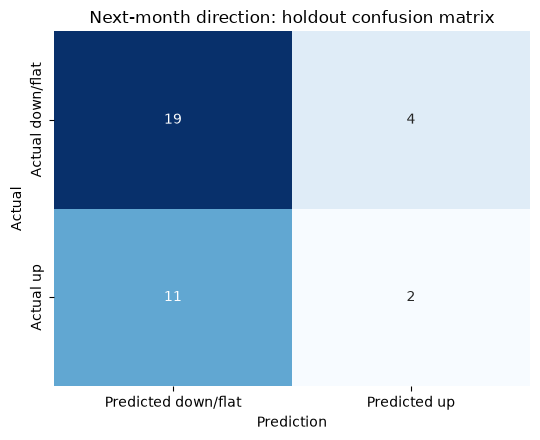

In [32]:
cm = confusion_matrix(actual_dir, pred_dir, labels=[0,1])
fig, ax = plt.subplots(figsize=(5.5,4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted down/flat','Predicted up'],
            yticklabels=['Actual down/flat','Actual up'], ax=ax)
ax.set(title='Next-month direction: holdout confusion matrix', xlabel='Prediction', ylabel='Actual')
fig.tight_layout(); plt.show()

### Chart 18 — Direction probability calibration

A reliability diagram compares predicted probability bins with the observed frequency of upward months. With a small holdout, individual bins can be noisy; do not interpret this chart as a stable probability calibration guarantee.

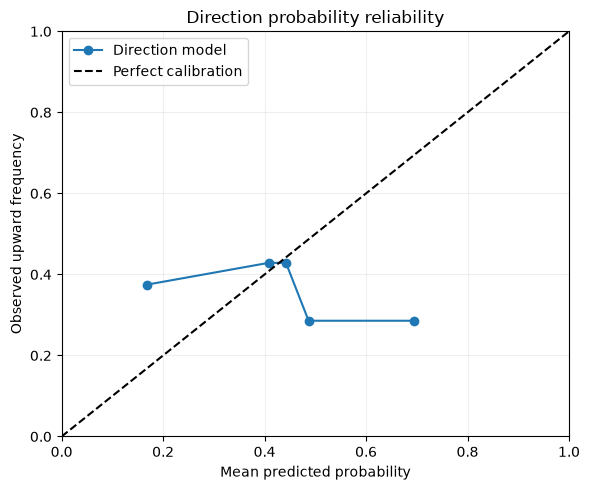

In [33]:
if actual_dir.nunique() == 2:
    frac_pos, mean_pred = calibration_curve(actual_dir, prob_dir, n_bins=min(5, max(2, len(actual_dir)//6)), strategy='quantile')
    fig, ax = plt.subplots(figsize=(6,5))
    ax.plot(mean_pred, frac_pos, marker='o', label='Direction model')
    ax.plot([0,1],[0,1], linestyle='--', color='black', label='Perfect calibration')
    ax.set(xlim=(0,1), ylim=(0,1), title='Direction probability reliability', xlabel='Mean predicted probability', ylabel='Observed upward frequency')
    ax.legend(); ax.grid(alpha=.2); fig.tight_layout(); plt.show()
else:
    print('Reliability chart skipped because the holdout contains only one class.')

# 9. Uncertainty quantification and residual diagnostics

Prediction intervals are estimated from absolute out-of-fold log-return residuals generated only inside the development sample. The 90% band is an **empirical time-series residual band**, not a guarantee of 90% future coverage: financial returns are dependent and can undergo structural breaks.

In [34]:
ALPHA = 0.10
interval_quantiles = {}
for h in HORIZONS:
    abs_resid = np.abs(cv_residuals[h])
    # 
    # Use the conservative higher empirical quantile for finite-sample calibration.
    interval_quantiles[h] = float(np.quantile(abs_resid, 1-ALPHA, method='higher'))
    result = walk_forward_results[h].copy()
    q = interval_quantiles[h]
    result['Lower_90'] = result['Anchor_Close'] * np.exp(result['ML_LogReturn'] - q)
    result['Upper_90'] = result['Anchor_Close'] * np.exp(result['ML_LogReturn'] + q)
    result['Covered_90'] = result['Actual_Close'].between(result['Lower_90'], result['Upper_90'])
    walk_forward_results[h] = result
    coverage = result['Covered_90'].mean()
    print(f'{h}-month horizon | OOF absolute log-return residual quantile: {q:.4f} | holdout empirical coverage: {coverage:.1%}')

1-month horizon | OOF absolute log-return residual quantile: 0.1928 | holdout empirical coverage: 63.9%
3-month horizon | OOF absolute log-return residual quantile: 0.2896 | holdout empirical coverage: 50.0%
6-month horizon | OOF absolute log-return residual quantile: 0.4079 | holdout empirical coverage: 22.6%


### Chart 19 — 1-month forecast with empirical 90% residual band

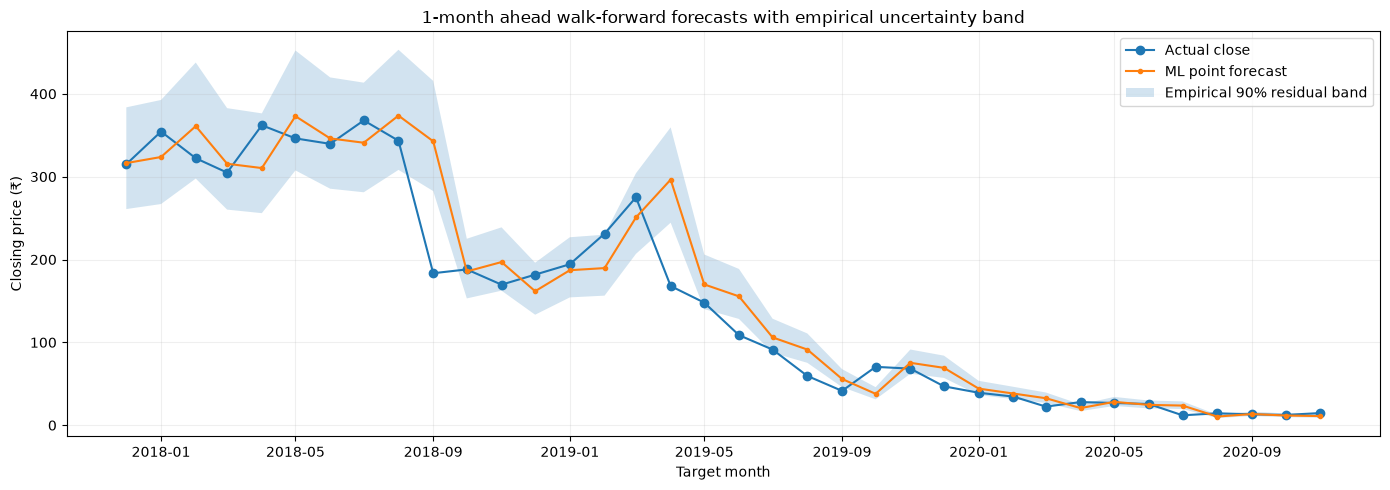

In [35]:
r = walk_forward_results[1]
fig, ax = plt.subplots(figsize=(14,5))
ax.plot(r['Target_Date'], r['Actual_Close'], marker='o', label='Actual close')
ax.plot(r['Target_Date'], r['ML_Predicted_Close'], marker='.', label='ML point forecast')
ax.fill_between(r['Target_Date'], r['Lower_90'], r['Upper_90'], alpha=.2, label='Empirical 90% residual band')
ax.set(title='1-month ahead walk-forward forecasts with empirical uncertainty band', xlabel='Target month', ylabel='Closing price (₹)')
ax.legend(); ax.grid(alpha=.2); fig.tight_layout(); plt.show()

### Chart 20 — Forecast residuals over time

Residual = actual future log return minus predicted future log return. Persistent runs above/below zero indicate systematic under- or over-prediction.

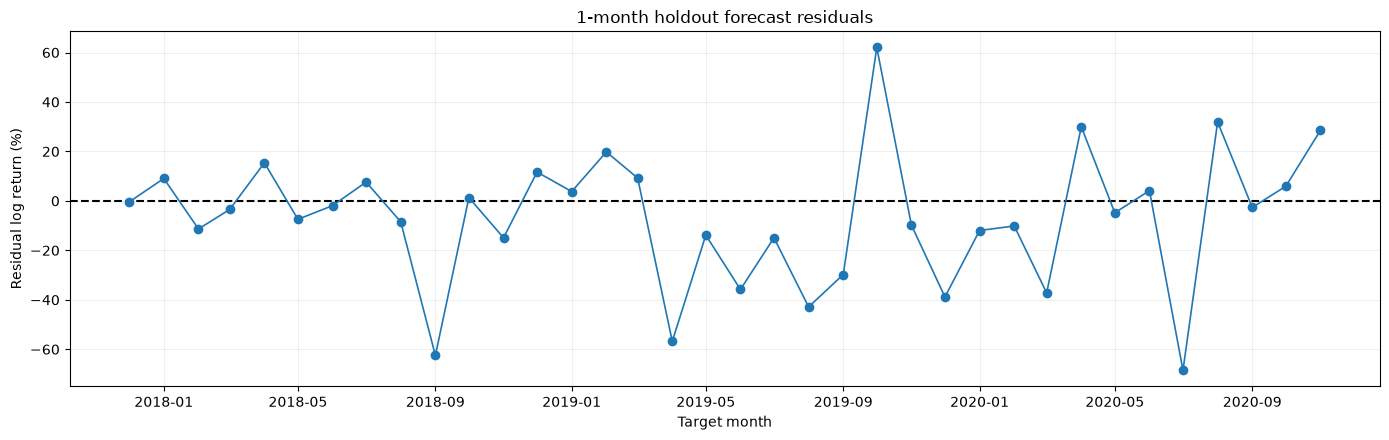

Residual mean: -0.0689 | Residual std: 0.2722


In [36]:
r = walk_forward_results[1].copy()
r['Residual'] = r['Actual_LogReturn'] - r['ML_LogReturn']
fig, ax = plt.subplots(figsize=(14,4.5))
ax.axhline(0, color='black', linestyle='--')
ax.plot(r['Target_Date'], r['Residual'] * 100, marker='o', linewidth=1.2)
ax.set(title='1-month holdout forecast residuals', xlabel='Target month', ylabel='Residual log return (%)')
ax.grid(alpha=.2); fig.tight_layout(); plt.show()
print('Residual mean:', round(float(r['Residual'].mean()),4), '| Residual std:', round(float(r['Residual'].std()),4))

### Chart 21 — Residual distribution and Q-Q diagnostic

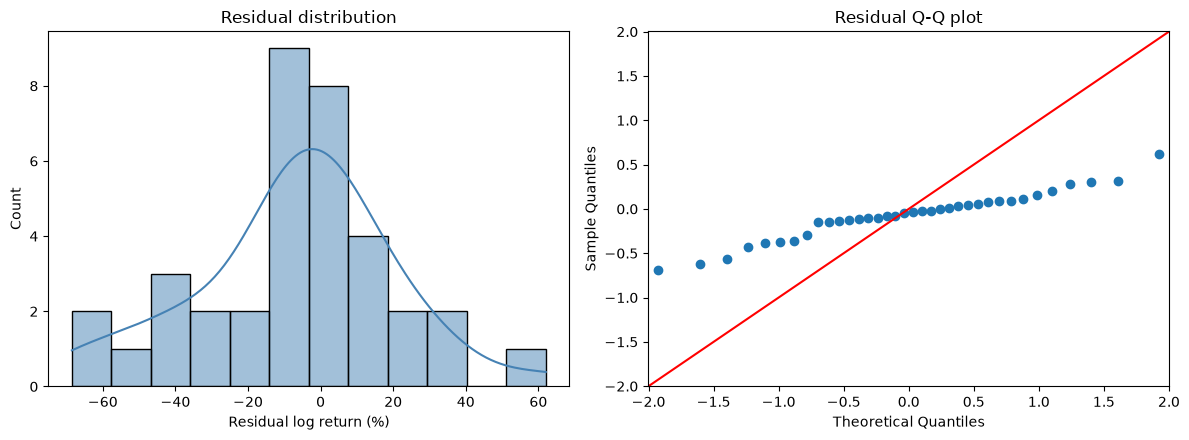

In [37]:
resid = r['Residual'].to_numpy()
fig, axes = plt.subplots(1,2,figsize=(12,4.5))
sns.histplot(resid*100, bins=12, kde=True, color='steelblue', ax=axes[0])
axes[0].set(title='Residual distribution', xlabel='Residual log return (%)')
sm.qqplot(resid, line='45', ax=axes[1])
axes[1].set_title('Residual Q-Q plot')
fig.tight_layout(); plt.show()

### Chart 22 — Residual autocorrelation

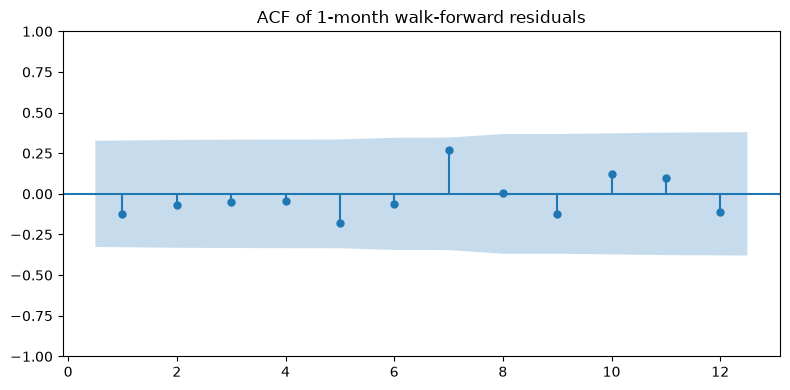

,lb_stat,lb_pvalue
6,2.6133,0.8556
12,8.8281,0.7175


In [38]:
fig, ax = plt.subplots(figsize=(8,4))
plot_acf(r['Residual'], lags=min(12, max(3, len(r)//3)), zero=False, ax=ax)
ax.set_title('ACF of 1-month walk-forward residuals')
fig.tight_layout(); plt.show()
if len(r) > 12:
    display(acorr_ljungbox(r['Residual'], lags=[6, min(12,len(r)-1)], return_df=True))
else:
    print('Ljung–Box residual test skipped: too few holdout observations.')

# 10. Feature interpretation and volatility-regime review

Permutation importance measures how much a model's score worsens when a feature is shuffled. It is a model-specific predictive diagnostic, not a causal effect. Correlated features can share or dilute importance.

In [39]:
# The last walk-forward estimator is trained only on labels matured before its forecast origin.
# Permutation on the holdout is post-evaluation explanation, not model-selection input.
final_estimator_1m = clone(selected_estimators[1]).fit(*training_sets[1])
X_test_1m = features.iloc[walk_forward_results[1]['Origin_Index'].to_numpy()]
y_test_1m = walk_forward_results[1]['Actual_LogReturn'].to_numpy()
perm = permutation_importance(
    final_estimator_1m, X_test_1m, y_test_1m,
    scoring='neg_mean_absolute_error', n_repeats=20,
    random_state=RANDOM_STATE, n_jobs=1
)
importance = pd.DataFrame({
    'Feature':features.columns,
    'Importance_Mean':perm.importances_mean,
    'Importance_Std':perm.importances_std,
}).sort_values('Importance_Mean', ascending=False)
display(importance.head(15))

,Feature,Importance_Mean,Importance_Std
11,return_volatility_3,0.0006,0.0004
1,intramonth_body_log,0.0005,0.0008
19,return_volatility_12,0.0004,0.0010
24,month_sin,0.0002,0.0006
0,opening_gap_log,0.0002,0.0002
3,close_location,0.0002,0.0013
2,high_low_range_log,0.0002,0.0001
7,return_lag_6,0.0002,0.0002
20,momentum_12,0.0001,0.0002
9,return_lag_12,0.0001,0.0003


### Chart 23 — Holdout permutation feature importance

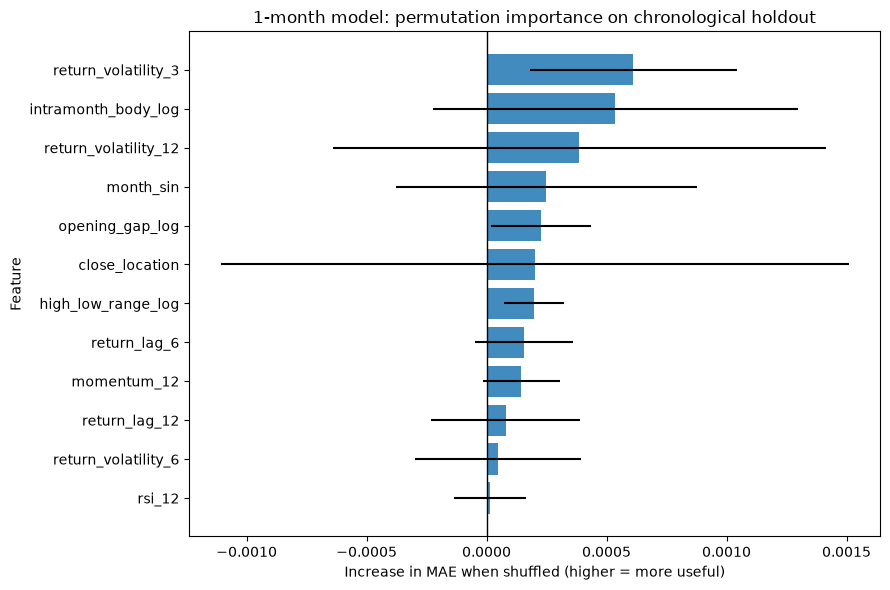

In [40]:
top_imp = importance.head(12).sort_values('Importance_Mean')
fig, ax = plt.subplots(figsize=(9,6))
ax.barh(top_imp['Feature'], top_imp['Importance_Mean'], xerr=top_imp['Importance_Std'], alpha=.85)
ax.axvline(0, color='black', linewidth=1)
ax.set(title='1-month model: permutation importance on chronological holdout', xlabel='Increase in MAE when shuffled (higher = more useful)', ylabel='Feature')
fig.tight_layout(); plt.show()

### Volatility-regime error review

A high-volatility threshold is computed from pre-holdout 12-month realized volatility only. Holdout errors are then compared between high- and lower-volatility observations. This is a descriptive slice, not a separate tuning exercise.

In [41]:
rolling_vol = eda['Log_Return'].rolling(12).std()
train_vol = rolling_vol.iloc[:HOLDOUT_START].dropna()
vol_threshold = float(train_vol.quantile(0.70))
regime_rows = walk_forward_results[1].copy()
regime_rows['Origin_Rolling_Vol'] = rolling_vol.iloc[regime_rows['Origin_Index']].to_numpy()
regime_rows['Volatility_Regime'] = np.where(regime_rows['Origin_Rolling_Vol'] >= vol_threshold, 'High volatility', 'Lower volatility')
regime_rows['Absolute_Error_Rupees'] = np.abs(regime_rows['Actual_Close'] - regime_rows['ML_Predicted_Close'])
regime_summary = regime_rows.groupby('Volatility_Regime').agg(
    Observations=('Absolute_Error_Rupees','size'),
    MAE_Rupees=('Absolute_Error_Rupees','mean'),
    Mean_Rolling_Vol=('Origin_Rolling_Vol','mean')
).reset_index()
display(regime_summary)

,Volatility_Regime,Observations,MAE_Rupees,Mean_Rolling_Vol
0,High volatility,26,18.9083,0.2632
1,Lower volatility,10,38.3020,0.0975


### Chart 24 — Forecast error by volatility regime

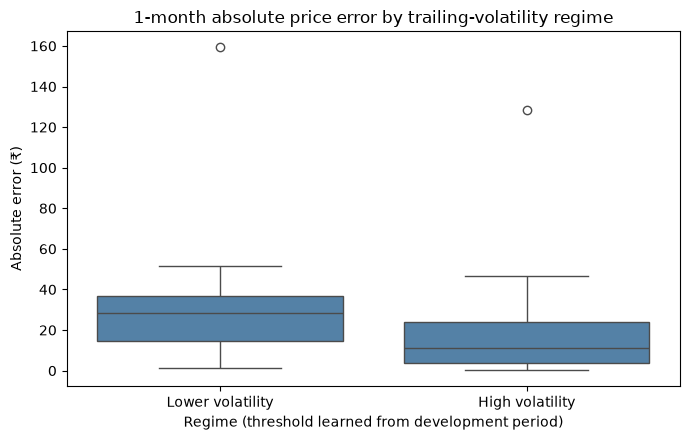

In [42]:
fig, ax = plt.subplots(figsize=(7,4.5))
sns.boxplot(data=regime_rows, x='Volatility_Regime', y='Absolute_Error_Rupees', color='steelblue', ax=ax)
ax.set(title='1-month absolute price error by trailing-volatility regime', xlabel='Regime (threshold learned from development period)', ylabel='Absolute error (₹)')
fig.tight_layout(); plt.show()

### Chart 29 — Forecast error stability by target year

This diagnostic checks whether one-month holdout price errors are concentrated in particular calendar years. It is a small-sample stability review, not a causal event study.

,Target_Year,MAE_INR,Observations
0,2017,1.3397,1
1,2018,35.9530,12
2,2019,32.7570,12
3,2020,4.4342,11


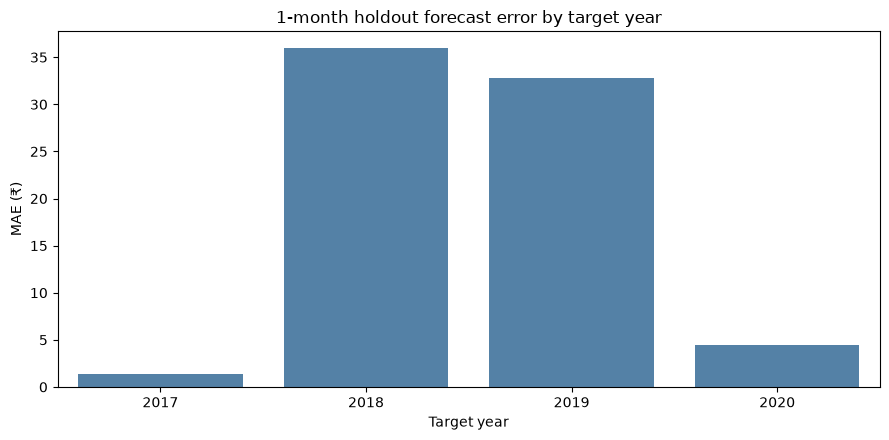

In [43]:
annual_error = walk_forward_results[1].copy()
annual_error['Target_Year'] = pd.to_datetime(annual_error['Target_Date']).dt.year
annual_error['Absolute_Error_INR'] = (annual_error['Actual_Close'] - annual_error['ML_Predicted_Close']).abs()
annual_error_summary = annual_error.groupby('Target_Year').agg(
    MAE_INR=('Absolute_Error_INR', 'mean'),
    Observations=('Absolute_Error_INR', 'size')
).reset_index()
display(annual_error_summary)
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=annual_error_summary, x='Target_Year', y='MAE_INR', color='steelblue', ax=ax)
ax.set(title='1-month holdout forecast error by target year', xlabel='Target year', ylabel='MAE (₹)')
fig.tight_layout(); plt.show()

# 11. Decision test: a transparent long/flat simulation

This is an educational backtest over the final chronological holdout. A long position is taken only when the predicted next-month simple return exceeds an assumed one-way transaction cost. Positions are long or flat; no leverage or shorting is used. The signal is generated from the forecast at the origin, and the realized close-to-close return is applied to the following interval.

**Important assumptions:** transaction cost is set to 0.10% per entry or exit, taxes, spread, slippage, funding and liquidity are not modelled, and trading at the exact monthly closing price is an idealization. A 30–36 observation holdout is too short to establish a robust trading edge.

In [44]:
ONE_WAY_TRANSACTION_COST = 0.001  # Editable assumption: 0.10% per entry or exit.
STRATEGY_RETURN_THRESHOLD = ONE_WAY_TRANSACTION_COST

bt = walk_forward_results[1].copy().sort_values('Origin_Date').reset_index(drop=True)
bt['Actual_Simple_Return'] = np.exp(bt['Actual_LogReturn']) - 1
bt['Predicted_Simple_Return'] = np.exp(bt['ML_LogReturn']) - 1
bt['Position'] = (bt['Predicted_Simple_Return'] > STRATEGY_RETURN_THRESHOLD).astype(int)
previous_position = bt['Position'].shift(1).fillna(0)
bt['Turnover'] = (bt['Position'] - previous_position).abs()
bt['Strategy_Net_Return'] = bt['Position'] * bt['Actual_Simple_Return'] - bt['Turnover'] * ONE_WAY_TRANSACTION_COST

# Buy-and-hold reference: always invested; pay one initial entry cost.
bt['BuyHold_Net_Return'] = bt['Actual_Simple_Return'].copy()
if len(bt):
    bt.loc[bt.index[0], 'BuyHold_Net_Return'] -= ONE_WAY_TRANSACTION_COST

for label, col in [('Strategy','Strategy_Net_Return'), ('Buy & hold','BuyHold_Net_Return')]:
    bt[f'{label}_Wealth'] = (1 + bt[col]).cumprod()
    wealth = bt[f'{label}_Wealth']
    monthly = bt[col]
    ann_return = wealth.iloc[-1] ** (12/len(bt)) - 1 if len(bt) else np.nan
    ann_vol = monthly.std(ddof=1) * np.sqrt(12) if len(bt)>1 else np.nan
    sharpe = monthly.mean()/monthly.std(ddof=1)*np.sqrt(12) if len(bt)>1 and monthly.std(ddof=1)>0 else np.nan
    drawdown = (wealth/wealth.cummax()-1).min()
    print(f'{label}: cumulative return={wealth.iloc[-1]-1:.1%}, annualized return={ann_return:.1%}, '
          f'annualized volatility={ann_vol:.1%}, Sharpe (rf=0)={sharpe:.2f}, max drawdown={drawdown:.1%}')
print('Number of position changes:', int(bt['Turnover'].sum()))
display(bt[['Origin_Date','Target_Date','Predicted_Simple_Return','Actual_Simple_Return','Position','Turnover','Strategy_Net_Return']].head(10))

Strategy: cumulative return=-64.7%, annualized return=-29.3%, annualized volatility=39.0%, Sharpe (rf=0)=-0.65, max drawdown=-74.8%
Buy & hold: cumulative return=-95.2%, annualized return=-63.7%, annualized volatility=81.7%, Sharpe (rf=0)=-0.76, max drawdown=-96.8%
Number of position changes: 16


,Origin_Date,Target_Date,Predicted_Simple_Return,Actual_Simple_Return,Position,Turnover,Strategy_Net_Return
0,2017-11-01,2017-12-01,0.0313,0.0269,1,1.0000,0.0259
1,2017-12-01,2018-01-01,0.0276,0.1251,1,0.0000,0.1251
2,2018-01-01,2018-02-01,0.0185,-0.0908,1,0.0000,-0.0908
3,2018-02-01,2018-03-01,-0.0207,-0.0538,0,1.0000,-0.0010
4,2018-03-01,2018-04-01,0.0180,0.1874,1,1.0000,0.1864
5,2018-04-01,2018-05-01,0.0302,-0.0438,1,0.0000,-0.0438
6,2018-05-01,2018-06-01,-0.0001,-0.0191,0,1.0000,-0.0010
7,2018-06-01,2018-07-01,0.0040,0.0833,1,1.0000,0.0823
8,2018-07-01,2018-08-01,0.0158,-0.0666,1,0.0000,-0.0666
9,2018-08-01,2018-09-01,-0.0021,-0.4658,0,1.0000,-0.0010


### Chart 25 — Strategy versus buy-and-hold equity curve

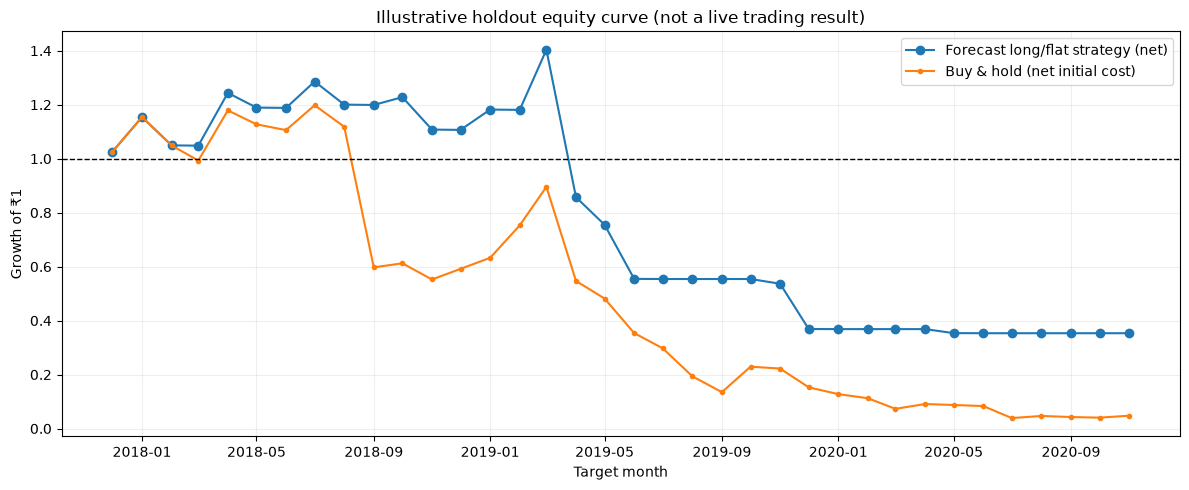

In [45]:
fig, ax = plt.subplots(figsize=(12,5))
ax.plot(bt['Target_Date'], bt['Strategy_Wealth'], marker='o', label='Forecast long/flat strategy (net)')
ax.plot(bt['Target_Date'], bt['Buy & hold_Wealth'], marker='.', label='Buy & hold (net initial cost)')
ax.axhline(1, color='black', linestyle='--', linewidth=1)
ax.set(title='Illustrative holdout equity curve (not a live trading result)', xlabel='Target month', ylabel='Growth of ₹1')
ax.legend(); ax.grid(alpha=.2); fig.tight_layout(); plt.show()

### Chart 26 — Strategy drawdown

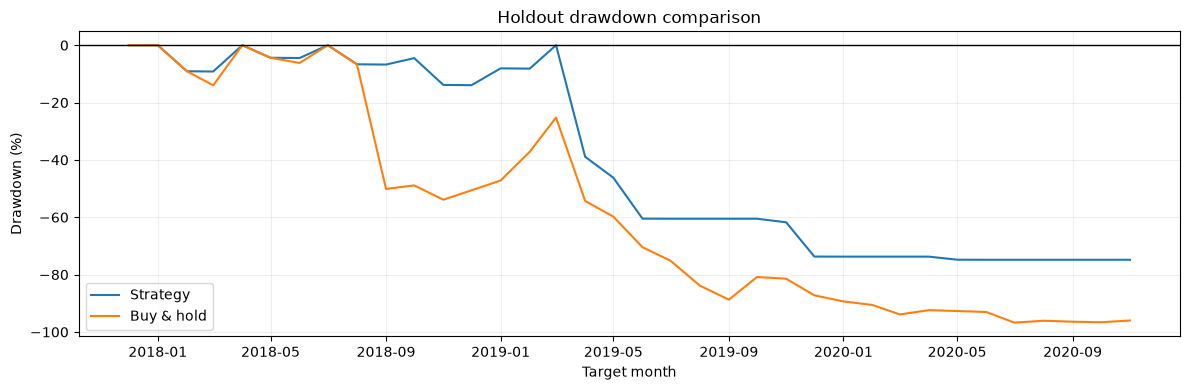

In [46]:
fig, ax = plt.subplots(figsize=(12,4))
for label, col in [('Strategy','Strategy_Wealth'), ('Buy & hold','Buy & hold_Wealth')]:
    dd = bt[col] / bt[col].cummax() - 1
    ax.plot(bt['Target_Date'], dd*100, label=label)
ax.axhline(0, color='black', linewidth=1)
ax.set(title='Holdout drawdown comparison', xlabel='Target month', ylabel='Drawdown (%)')
ax.legend(); ax.grid(alpha=.2); fig.tight_layout(); plt.show()

### Chart 30 — Transaction-cost sensitivity

The strategy is re-evaluated across several explicit one-way cost assumptions. Both the entry threshold and turnover costs change with the assumption. This is a sensitivity analysis, not a calibrated estimate of actual YES BANK execution costs.

,One_way_cost_pct,Cumulative_strategy_return_pct,Position_changes,Invested_months
0,0.0000,-76.6127,18,18
1,0.1000,-64.6678,16,17
2,0.3000,-65.7527,16,17
3,0.5000,-69.3825,16,16
4,1.0000,-69.9430,14,15


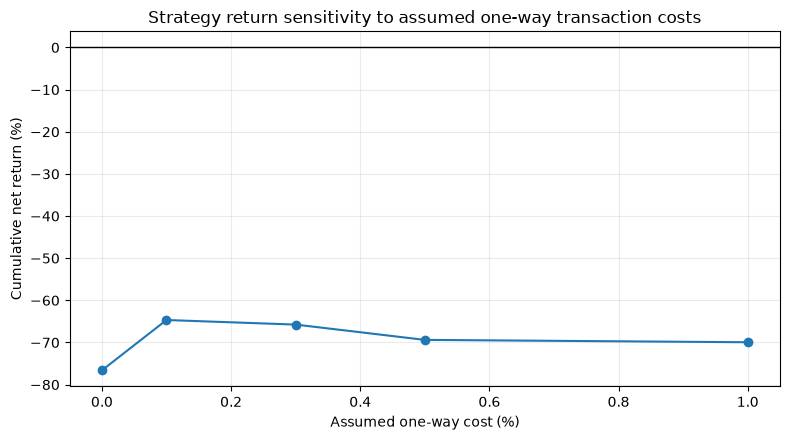

In [47]:
cost_sensitivity_rows = []
for cost in [0.0, 0.001, 0.003, 0.005, 0.01]:
    predicted_return = bt['Predicted_Simple_Return'].to_numpy()
    realized_return = bt['Actual_Simple_Return'].to_numpy()
    position = (predicted_return > cost).astype(int)
    previous = np.r_[0, position[:-1]]
    turnover = np.abs(position - previous)
    net_return = position * realized_return - turnover * cost
    wealth = float(np.prod(1 + net_return))
    cost_sensitivity_rows.append({
        'One_way_cost_pct': cost * 100,
        'Cumulative_strategy_return_pct': (wealth - 1) * 100,
        'Position_changes': int(turnover.sum()),
        'Invested_months': int(position.sum()),
    })
cost_sensitivity = pd.DataFrame(cost_sensitivity_rows)
display(cost_sensitivity)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(cost_sensitivity['One_way_cost_pct'], cost_sensitivity['Cumulative_strategy_return_pct'], marker='o')
ax.axhline(0, color='black', linewidth=1)
ax.set(title='Strategy return sensitivity to assumed one-way transaction costs',
       xlabel='Assumed one-way cost (%)', ylabel='Cumulative net return (%)')
ax.grid(alpha=.25); fig.tight_layout(); plt.show()

## Forecast loss comparison: HAC-robust loss-differential test

For each horizon, the loss differential is `|baseline error| − |ML error|` in log-return space. A positive mean means the ML model had lower absolute error. A Newey–West/HAC covariance estimate is used to reduce sensitivity to serial dependence. With this small holdout, treat the p-value as a diagnostic, not decisive evidence of model superiority.

In [48]:
loss_test_rows = []
for h, result in walk_forward_results.items():
    d = (np.abs(result['Actual_LogReturn'] - result['Persistence_LogReturn']) -
         np.abs(result['Actual_LogReturn'] - result['ML_LogReturn'])).dropna().to_numpy()
    if len(d) >= 8:
        hac_lags = min(h-1, max(0, len(d)//4))
        fit = sm.OLS(d, np.ones((len(d),1))).fit(cov_type='HAC', cov_kwds={'maxlags':hac_lags})
        z = float(fit.tvalues[0])
        p_one_sided = float(stats.norm.sf(z))
        loss_test_rows.append({'Horizon':h,'Mean loss advantage for ML':float(d.mean()),
                               'HAC z statistic':z,'One-sided p-value':p_one_sided,
                               'HAC maxlags':hac_lags,'N':len(d)})
    else:
        loss_test_rows.append({'Horizon':h,'Mean loss advantage for ML':float(d.mean()),
                               'HAC z statistic':np.nan,'One-sided p-value':np.nan,
                               'HAC maxlags':np.nan,'N':len(d)})
display(pd.DataFrame(loss_test_rows))

,Horizon,Mean loss advantage for ML,HAC z statistic,One-sided p-value,HAC maxlags,N
0,1,-0.0066,-0.7660,0.7782,0,36
1,3,-0.0185,-2.1892,0.9857,2,34
2,6,-0.1043,-2.5292,0.9943,5,31


# 12. Final forecast, model persistence and operational checklist

The forecast below is anchored to the final historical row in the uploaded file. It is useful to demonstrate the fitted pipeline and the saved model interface, but it is not a forecast for today's market. For a live forecast, the dataset must first be updated and the model revalidated using current data.

In [49]:
# Refit each selected model on all labels that are fully observed by the final historical date.
last_index = len(df) - 1
final_models = {}
forecast_rows = []

for h in HORIZONS:
    origins = np.flatnonzero(feature_ok.to_numpy() & targets[h].notna().to_numpy())
    matured = origins[(origins + h) <= last_index]
    final_model = clone(selected_estimators[h])
    final_model.fit(features.iloc[matured], targets[h].iloc[matured])
    final_models[h] = final_model
    predicted_log_return = float(final_model.predict(features.iloc[[last_index]])[0])
    anchor_close = float(df.loc[last_index, 'Close'])
    q = interval_quantiles[h]
    forecast_rows.append({
        'Horizon_months':h,
        'Historical_target_date':df.loc[last_index,'Date'] + pd.DateOffset(months=h),
        'Anchor_close_INR':anchor_close,
        'Predicted_log_return':predicted_log_return,
        'Predicted_close_INR':anchor_close*np.exp(predicted_log_return),
        'Empirical_lower_band_INR':anchor_close*np.exp(predicted_log_return-q),
        'Empirical_upper_band_INR':anchor_close*np.exp(predicted_log_return+q),
        'Selected_model':best_by_horizon[h]['Model'],
        'CV_MAE_log_return':best_by_horizon[h]['CV_MAE_LogReturn'],
    })

historical_forecasts = pd.DataFrame(forecast_rows)
display(historical_forecasts)
print('Forecast anchor date:', df.loc[last_index,'Date'].strftime('%B %Y'))
print('This table is a historical demonstration only; source data do not extend beyond November 2020.')

,Horizon_months,Historical_target_date,Anchor_close_INR,Predicted_log_return,Predicted_close_INR,Empirical_lower_band_INR,Empirical_upper_band_INR,Selected_model,CV_MAE_log_return
0,1,2020-12-01,14.6700,-0.0611,13.8007,11.3806,16.7356,Extra Trees,0.0871
1,3,2021-02-01,14.6700,-0.0052,14.5944,10.9247,19.4968,Elastic Net,0.1533
2,6,2021-05-01,14.6700,-0.0935,13.3607,8.8858,20.0892,Elastic Net,0.2009


Forecast anchor date: November 2020
This table is a historical demonstration only; source data do not extend beyond November 2020.


### Chart 27 — Historical 1-, 3- and 6-month forecast ranges

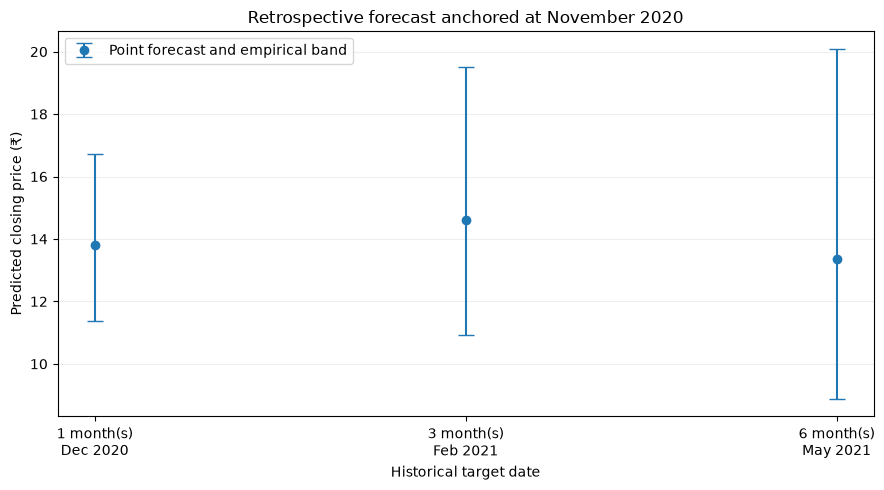

In [50]:
fig, ax = plt.subplots(figsize=(9,5))
plot_fc = historical_forecasts.sort_values('Horizon_months')
xpos = np.arange(len(plot_fc))
ax.errorbar(xpos, plot_fc['Predicted_close_INR'],
            yerr=[plot_fc['Predicted_close_INR']-plot_fc['Empirical_lower_band_INR'],
                  plot_fc['Empirical_upper_band_INR']-plot_fc['Predicted_close_INR']],
            fmt='o', capsize=6, label='Point forecast and empirical band')
ax.set_xticks(xpos, [f"{h} month(s)\n{d:%b %Y}" for h,d in zip(plot_fc['Horizon_months'],plot_fc['Historical_target_date'])])
ax.set(title='Retrospective forecast anchored at November 2020', ylabel='Predicted closing price (₹)', xlabel='Historical target date')
ax.grid(axis='y',alpha=.2); ax.legend(); fig.tight_layout(); plt.show()

## Save a reproducible model bundle

The bundle stores the horizon-specific fitted estimators, feature contract, model choices, source data cutoff and the empirical residual quantiles. The CSV is not embedded in the model artifact.

In [51]:
BUNDLE_PATH = Path('YES_BANK_advanced_model_bundle.joblib')
SCHEMA_PATH = Path('YES_BANK_feature_schema.json')

model_bundle = {
    'project': 'YES BANK Regime-Aware Multi-Horizon Forecasting',
    'training_data_start': str(df['Date'].min().date()),
    'training_data_end': str(df['Date'].max().date()),
    'target_definition': 'future log return from origin close to horizon close',
    'horizons_months': HORIZONS,
    'feature_columns': features.columns.tolist(),
    'models': final_models,
    'residual_quantiles_abs_log_return': interval_quantiles,
    'selected_model_names': {h:best_by_horizon[h]['Model'] for h in HORIZONS},
    'selected_parameters': {h:best_by_horizon[h]['Parameters'] for h in HORIZONS},
    'random_state': RANDOM_STATE,
}
joblib.dump(model_bundle, BUNDLE_PATH)
SCHEMA_PATH.write_text(json.dumps({
    'feature_columns':features.columns.tolist(),
    'horizons_months':HORIZONS,
    'training_data_end':str(df['Date'].max().date()),
    'target_definition':'future log return from origin close to horizon close',
}, indent=2))
print('Saved:', BUNDLE_PATH.resolve())
print('Saved:', SCHEMA_PATH.resolve())

Saved: C:\Users\sharm\Downloads\yes_bank\YES_BANK_advanced_model_bundle.joblib
Saved: C:\Users\sharm\Downloads\yes_bank\YES_BANK_feature_schema.json


### Reload and run a prediction sanity check

A model artifact is not deployment-ready merely because `joblib.dump` succeeds. Reloading and validating the interface checks that the saved model and feature schema are usable.

In [52]:
loaded_bundle = joblib.load(BUNDLE_PATH)
latest_feature_row = features.iloc[[last_index]][loaded_bundle['feature_columns']]
reloaded_check = []
for h in loaded_bundle['horizons_months']:
    pred_lr = float(loaded_bundle['models'][h].predict(latest_feature_row)[0])
    pred_close = float(df.loc[last_index,'Close'] * np.exp(pred_lr))
    reloaded_check.append({'Horizon_months':h,'Reloaded_prediction_INR':pred_close})
reloaded_check = pd.DataFrame(reloaded_check)
display(reloaded_check)
assert reloaded_check['Reloaded_prediction_INR'].notna().all()
assert (reloaded_check['Reloaded_prediction_INR'] > 0).all()
print('Reload test passed: all forecast outputs are finite and positive.')

,Horizon_months,Reloaded_prediction_INR
0,1,13.8007
1,3,14.5944
2,6,13.3607


Reload test passed: all forecast outputs are finite and positive.


## Reusable prediction function

This function accepts a recent OHLC history with the same columns. It validates the input, rebuilds only trailing features and uses the saved bundle. The supplied history must end at a completed monthly observation.

In [53]:
def predict_from_ohlc_history(history: pd.DataFrame, bundle_path=BUNDLE_PATH) -> pd.DataFrame:
    """Generate multi-horizon forecasts from an OHLC history."""
    required = {'Date','Open','High','Low','Close'}
    if not isinstance(history, pd.DataFrame):
        raise TypeError('history must be a pandas DataFrame.')
    missing = required.difference(history.columns)
    if missing:
        raise ValueError(f'Missing required columns: {sorted(missing)}')
    x = history[['Date','Open','High','Low','Close']].copy()
    x['Date'] = pd.to_datetime(x['Date'], errors='coerce')
    if x['Date'].isna().any():
        raise ValueError('History contains invalid dates.')
    for col in ['Open','High','Low','Close']:
        x[col] = pd.to_numeric(x[col], errors='coerce')
    if x[['Open','High','Low','Close']].isna().any().any():
        raise ValueError('History contains missing/non-numeric OHLC values.')
    x = x.sort_values('Date').reset_index(drop=True)
    if x['Date'].duplicated().any() or (x[['Open','High','Low','Close']] <= 0).any().any():
        raise ValueError('History must have unique dates and positive OHLC values.')
    if (x['High'] < x[['Open','Close']].max(axis=1)).any() or (x['Low'] > x[['Open','Close']].min(axis=1)).any():
        raise ValueError('OHLC high/low constraints are violated.')
    bundle = joblib.load(bundle_path)
    f = build_feature_frame(x)
    if f.iloc[[-1]].isna().any().any():
        raise ValueError('Not enough historical observations to calculate all features.')
    latest = f.iloc[[-1]][bundle['feature_columns']]
    rows = []
    for h in bundle['horizons_months']:
        log_r = float(bundle['models'][h].predict(latest)[0])
        anchor = float(x['Close'].iloc[-1])
        q = float(bundle['residual_quantiles_abs_log_return'][h])
        rows.append({
            'Horizon_months':h,
            'Target_date':x['Date'].iloc[-1] + pd.DateOffset(months=h),
            'Predicted_close_INR':anchor*np.exp(log_r),
            'Empirical_lower_INR':anchor*np.exp(log_r-q),
            'Empirical_upper_INR':anchor*np.exp(log_r+q),
        })
    return pd.DataFrame(rows)

# Sanity check the reusable function using the historical source data.
function_check = predict_from_ohlc_history(df)
display(function_check)

,Horizon_months,Target_date,Predicted_close_INR,Empirical_lower_INR,Empirical_upper_INR
0,1,2020-12-01,13.8007,11.3806,16.7356
1,3,2021-02-01,14.5944,10.9247,19.4968
2,6,2021-05-01,13.3607,8.8858,20.0892


# 13. Model recommendation and business interpretation

The final model choice is horizon-specific and is determined only by development-period time-series CV. The untouched holdout scorecard determines whether the chosen model actually improves on simple benchmarks. A selected ML model is **not** automatically recommended for deployment if it fails to beat persistence or seasonal-naïve forecasts on the holdout.

In [54]:
recommendation_rows = []
for h in HORIZONS:
    metrics_h = holdout_metrics[holdout_metrics['Horizon'] == h].copy()
    ml_name = 'Selected ML: ' + best_by_horizon[h]['Model']
    ml_row = metrics_h[metrics_h['Forecast'] == ml_name].iloc[0]
    baseline_rows = metrics_h[metrics_h['Forecast'].isin(['Persistence','Expanding drift','Seasonal naive','ARIMA(1,1,0)'])]
    best_base = baseline_rows.loc[baseline_rows['MAE_Rupees'].idxmin()]
    beats_best_base = bool(ml_row['MAE_Rupees'] < best_base['MAE_Rupees'])
    recommendation_rows.append({
        'Horizon_months':h,
        'CV_selected_model':best_by_horizon[h]['Model'],
        'ML_holdout_MAE_INR':ml_row['MAE_Rupees'],
        'Best_baseline':best_base['Forecast'],
        'Best_baseline_holdout_MAE_INR':best_base['MAE_Rupees'],
        'ML_beats_best_baseline':beats_best_base,
        'Recommendation':'Continue as candidate; evidence of incremental value on this holdout.' if beats_best_base else 'Do not promote over baseline; collect more data / improve predictors.'
    })
recommendation_table = pd.DataFrame(recommendation_rows)
display(recommendation_table)

print('\nPrimary recommendation:')
if recommendation_table['ML_beats_best_baseline'].any():
    print('At least one horizon shows lower holdout MAE than its strongest baseline. Review risk, uncertainty and sample size before use.')
else:
    print('No ML horizon beats its strongest naïve or ARIMA statistical benchmark by holdout MAE. Retain the best benchmark as the reference and do not claim ML superiority.')

,Horizon_months,CV_selected_model,ML_holdout_MAE_INR,Best_baseline,Best_baseline_holdout_MAE_INR,ML_beats_best_baseline,Recommendation
0,1,Extra Trees,24.2954,Persistence,23.7964,False,Do not promote over baseline; collect more dat...
1,3,Elastic Net,47.4200,Persistence,43.2294,False,Do not promote over baseline; collect more dat...
2,6,Elastic Net,92.1994,Persistence,72.6981,False,Do not promote over baseline; collect more dat...



Primary recommendation:
No ML horizon beats its strongest naïve or ARIMA statistical benchmark by holdout MAE. Retain the best benchmark as the reference and do not claim ML superiority.


### Evaluation metrics and business meaning

- **MAE (₹):** Average absolute price error; easiest to explain in rupees.
- **RMSE (₹):** Penalizes occasional large misses more heavily than MAE.
- **MAPE / sMAPE (%):** Relative error measures, useful across price levels but sensitive to low denominators and outliers.
- **Log-return MAE:** Evaluates the model on the target it was trained to predict.
- **Direction accuracy:** Fraction of months where the model predicts the correct sign; it ignores the size of gains and losses.
- **Balanced accuracy / ROC-AUC / Brier (classifier):** Secondary diagnostics for the direction experiment. Accuracy alone does not demonstrate a tradable edge.
- **Prediction-band coverage:** Proportion of realized prices inside the empirical band; coverage can drift when the return distribution changes.
- **Sharpe / drawdown (strategy simulation):** Risk-adjusted return and peak-to-trough loss under explicit, simplified transaction assumptions. They are not evidence of deployable performance on this small holdout.

# 14. Future work and production hardening

1. Add properly adjusted daily or weekly data, volume, market index returns, sector returns, corporate actions and macro/financial predictors, subject to source licensing.
2. Use a longer and regularly refreshed history; 185 monthly rows are insufficient for a high-capacity model.
3. Repeat rolling-origin evaluation across multiple historical cutoffs and reserve a truly recent period for final testing.
4. Investigate structural breaks and changing volatility; use regime-switching or probabilistic forecasting only when enough observations are available.
5. Calibrate prediction intervals on a rolling window and monitor empirical coverage drift.
6. Add spread, slippage, taxes, liquidity and execution timing before using any trading simulation for a decision.
7. Monitor MAE, directional accuracy, residual bias, feature drift, prediction-band coverage and benchmark-relative performance.
8. Retrain only under a documented schedule or performance trigger; version the data, features, model artifacts and evaluation reports.

**Operational warning:** The supplied file ends in November 2020. Update and revalidate the dataset before any contemporary use.

# Conclusion

This project turns the YES BANK OHLC history into a time-aware forecasting experiment rather than a random-split regression exercise. It validates the source data, creates indicators from information available at each monthly close, compares multiple model families and simple benchmarks, and evaluates forecasts using expanding-window cross-validation and walk-forward holdout predictions at one-, three- and six-month horizons. The analysis also examines stationarity, return dependence, volatility regimes, feature-ablation value, a fixed ARIMA statistical comparator, forecast uncertainty, feature importance and transaction-cost sensitivity in an illustrative strategy.

The key success criterion is incremental value over naïve and statistical benchmarks—not model complexity. The feature-ablation experiment also tests whether adding many technical indicators helps, rather than assuming that a larger feature set is better. Read the generated scorecards and recommendation table before making a final claim. If the selected ML model does not improve on the best baseline in the untouched chronological holdout, the defensible conclusion is that the current OHLC-only dataset has not shown enough predictive value to justify deployment. The dataset is short, ends in November 2020 and excludes market-wide or fundamental variables; all reported forecasts are therefore historical demonstrations with material uncertainty.

The strongest next step is to acquire a longer, current and richer dataset, preserve the same leakage-safe evaluation design, and require repeated out-of-time evidence before any real-world use.

## Submission checklist

- [ ] Enter author name, contribution type, team member details and GitHub repository link.
- [ ] Keep the CSV file in the same folder as the notebook.
- [ ] Restart the kernel and run **all** cells from top to bottom.
- [ ] Inspect the holdout metric table and benchmark comparison before writing final claims.
- [ ] Verify that model artifacts are saved and that the reload sanity check passes.
- [ ] Do not describe the outputs as a current market forecast; the source ends in November 2020.
- [ ] Add current licensed data and repeat the validation before any contemporary use.

### Files created by this notebook

- `YES_BANK_advanced_model_bundle.joblib` — fitted horizon-specific models and metadata.
- `YES_BANK_feature_schema.json` — exact feature contract and target metadata.

**This notebook is a research and educational prototype. It is not investment advice and is not ready for live execution without updated data, independent validation and realistic transaction modelling.**